<a href="https://colab.research.google.com/github/MaanyaGupta/CSET343/blob/main/E23CSEU0728_CSET343_LAB3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Assignment 3: Acquisition, Cleaning, Preprocessing and Analysis of Medical Data
**Course:** CSET343 AI in Healthcare  |  **Modalities:** Tabular, Text, Image, Signal

| Part | Data type | Dataset | How it is obtained in Colab |
|---|---|---|---|
| A | Tabular | Pima Indians Diabetes | Downloaded automatically (GitHub mirror), or your own `diabetes.csv` if uploaded |
| B | Text | MTSamples medical transcriptions | Kaggle (`kagglehub`), or upload `mtsamples.csv` |
| C | Image | Chest X-Ray (Pneumonia) | Kaggle (`kagglehub`), or upload / unzip a `chest_xray` folder |
| D | Signal | MIT-BIH Arrhythmia (record 100) | Streamed automatically from PhysioNet with `wfdb` |


In [ ]:
!pip install -q wfdb nltk pydicom tqdm

In [ ]:
import os, re, sys, html, json, math, random, hashlib, warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, signal as sp_signal

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE); random.seed(RANDOM_STATE)

try:
    from tqdm.auto import tqdm
except Exception:
    tqdm = lambda x, **k: x

In [ ]:
def setup_kaggle():
    try:
        from google.colab import userdata
        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
        return "Colab secrets"
    except Exception:
        pass
    if "KAGGLE_USERNAME" in os.environ or os.path.exists(os.path.expanduser("~/.kaggle/kaggle.json")):
        return "existing credentials"
    return None

print("Kaggle credentials:", setup_kaggle() or "not found (anonymous / upload fallback will be tried)")

Kaggle credentials: Colab secrets


---
# Part A: Tabular Data (Pima Indians Diabetes)
768 women of Pima Indian heritage, 8 clinical measurements and a binary `Outcome` (1 = diabetes within 5 years).

## A1. Data Acquisition and Initial Inspection

In [ ]:
PIMA_COLS = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
             "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]
PIMA_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

if os.path.exists("diabetes.csv"):                       # Kaggle version (has a header row)
    pima_raw = pd.read_csv("diabetes.csv")
    pima_src = "local Kaggle file diabetes.csv"
else:                                                    # same data, no header row
    pima_raw = pd.read_csv(PIMA_URL, header=None, names=PIMA_COLS)
    pima_src = "GitHub mirror of the NIDDK/UCI data"

print("Source :", pima_src)
print("Shape  :", pima_raw.shape)
pima_raw.head()

Source : GitHub mirror of the NIDDK/UCI data
Shape  : (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
print("Data types:\n", pima_raw.dtypes, "\n")
print("Missing values (NaN):", int(pima_raw.isnull().sum().sum()))
pima_raw.describe().T.round(2)

Data types:
 Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object 

Missing values (NaN): 0


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


**Observation:** there are *no NaN values*, yet `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` and `BMI`
have a **minimum of 0**. A living patient cannot have 0 blood pressure or 0 BMI. In this dataset, missing measurements were
stored as 0, so the missingness is hidden behind valid-looking numbers (exactly the healthcare trap the assignment mentions).

## A2. Data Cleaning
1. Remove exact duplicate rows.
2. Treat implausible zeros as missing (`NaN`). `Pregnancies = 0` and `Outcome = 0` are valid, so they are left alone.
3. Impute with the **median** (robust for skewed lab values) and add a **missing-indicator** column for the two heavily
   affected features, because *whether* a value was measured can itself be clinically informative.

In [ ]:
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

zero_report = pd.DataFrame({
    "zeros": (pima_raw[zero_cols] == 0).sum(),
    "zero_%": ((pima_raw[zero_cols] == 0).mean() * 100).round(1),
})
display(zero_report)

# 1) exact duplicates
n_dup = int(pima_raw.duplicated().sum())
pima = pima_raw.drop_duplicates().reset_index(drop=True)
print(f"\nExact duplicate rows removed: {n_dup}  ->  {len(pima)} rows remain")

# 2) implausible zeros -> NaN
pima_nan = pima.copy()
pima_nan[zero_cols] = pima_nan[zero_cols].replace(0, np.nan)
print("\nMissing values after converting implausible zeros:")
display(pima_nan.isnull().sum().to_frame("missing").T)

,zeros,zero_%
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4



Exact duplicate rows removed: 0  ->  768 rows remain

Missing values after converting implausible zeros:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
missing,0,5,35,227,374,11,0,0,0


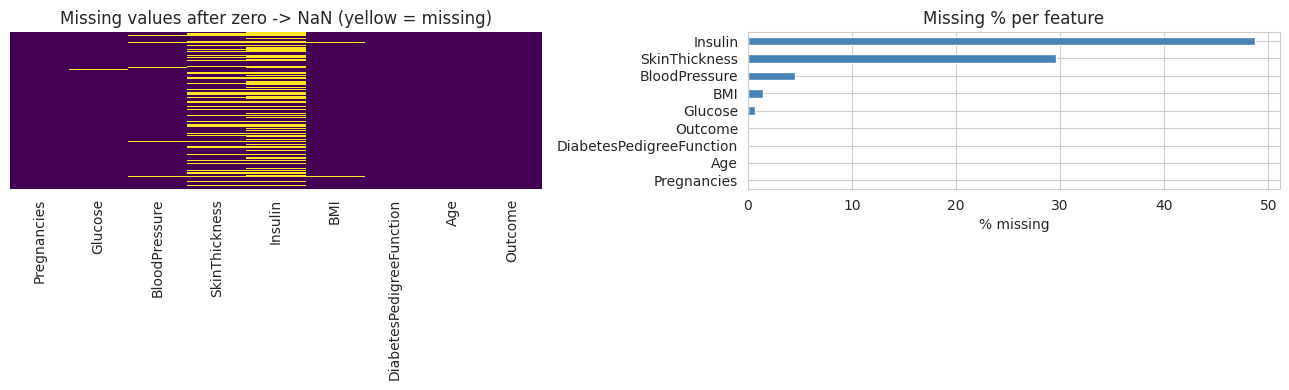

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(pima_nan.isnull(), cbar=False, yticklabels=False, cmap="viridis", ax=axes[0])
axes[0].set_title("Missing values after zero -> NaN (yellow = missing)")
(pima_nan.isnull().mean() * 100).sort_values().plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_xlabel("% missing"); axes[1].set_title("Missing % per feature")
plt.tight_layout(); plt.show()

Medians used for imputation:
 Glucose          117.0
BloodPressure     72.0
SkinThickness     29.0
Insulin          125.0
BMI               32.3 

Missing values left: 0


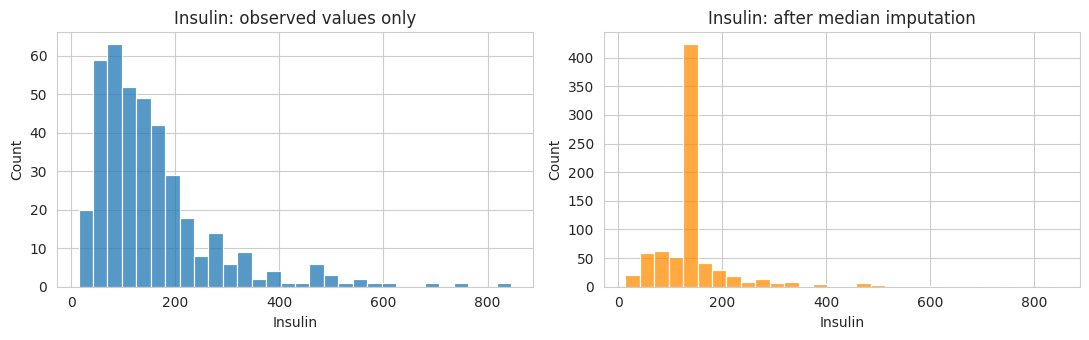

In [ ]:
pima_clean = pima_nan.copy()

# missing-indicator columns for the two worst features (keep the information that the value was absent)
for c in ["Insulin", "SkinThickness"]:
    pima_clean[f"{c}_missing"] = pima_clean[c].isna().astype(int)

medians = pima_clean[zero_cols].median()
print("Medians used for imputation:\n", medians.round(2).to_string(), "\n")
pima_clean[zero_cols] = pima_clean[zero_cols].fillna(medians)

print("Missing values left:", int(pima_clean[PIMA_COLS].isnull().sum().sum()))

# effect of imputation on the worst feature
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True)
sns.histplot(pima_nan["Insulin"].dropna(), bins=30, ax=axes[0]); axes[0].set_title("Insulin: observed values only")
sns.histplot(pima_clean["Insulin"], bins=30, ax=axes[1], color="darkorange"); axes[1].set_title("Insulin: after median imputation")
plt.tight_layout(); plt.show()

> **Caution.** Insulin is missing for ~49% of patients, so median imputation creates a tall spike (right plot).
> That is acceptable for this lab, but for real modelling the imputer should be fitted **inside** each training fold
> (`Pipeline`) to avoid leakage, and model-based imputers (KNN, iterative) are worth comparing.

## A3. Data Preprocessing
- Confirm the target is a clean binary integer.
- Split first (stratified), then **fit the scaler on the training set only**, so no test-set information leaks.
- Standardize the 8 original features to mean 0 / std 1 and convert to `float32` arrays (model-ready tensors).

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler

base_features = [c for c in PIMA_COLS if c != "Outcome"]

# ---- target check
assert set(pima_clean["Outcome"].unique()) == {0, 1}, "Outcome must be binary 0/1"
pima_clean["Outcome"] = pima_clean["Outcome"].astype(int)
print("Target dtype:", pima_clean["Outcome"].dtype, "| unique values:", sorted(pima_clean["Outcome"].unique()))
print(pima_clean["Outcome"].value_counts().rename({0: "0 (no diabetes)", 1: "1 (diabetes)"}).to_string())

# ---- split + scale
X = pima_clean[base_features]
y = pima_clean["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

scaler = StandardScaler().fit(X_train)
X_train_t = scaler.transform(X_train).astype("float32")
X_test_t = scaler.transform(X_test).astype("float32")
y_train_t, y_test_t = y_train.values.astype("float32"), y_test.values.astype("float32")

print("\nTrain tensor:", X_train_t.shape, "| Test tensor:", X_test_t.shape)
print("Train mean (should be ~0):", X_train_t.mean(axis=0).round(3))
print("Train std  (should be ~1):", X_train_t.std(axis=0).round(3))
print("Class ratio train/test  :", y_train.mean().round(3), "/", y_test.mean().round(3), "(stratified)")

Target dtype: int64 | unique values: [np.int64(0), np.int64(1)]
Outcome
0 (no diabetes)    500
1 (diabetes)       268

Train tensor: (614, 8) | Test tensor: (154, 8)
Train mean (should be ~0): [ 0. -0. -0.  0. -0. -0. -0.  0.]
Train std  (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1.]
Class ratio train/test  : 0.349 / 0.351 (stratified)


## A4. Inferential Statistics
### (i) Welch's t-test: do diabetic and non-diabetic patients differ on each feature?
- **H0:** mean of the feature is the same in both groups. **H1:** the means differ.
- Welch's version is used because it does not assume equal variances. A Mann-Whitney U test is added as a non-parametric
  check, and a Bonferroni-corrected threshold (0.05 / 8) accounts for testing 8 features at once.

In [ ]:
g0 = pima_clean[pima_clean["Outcome"] == 0]
g1 = pima_clean[pima_clean["Outcome"] == 1]

def cohens_d(a, b):
    n1, n2 = len(a), len(b)
    pooled = np.sqrt(((n1 - 1) * a.var(ddof=1) + (n2 - 1) * b.var(ddof=1)) / (n1 + n2 - 2))
    return (a.mean() - b.mean()) / pooled

rows = []
for f in base_features:
    t, p = stats.ttest_ind(g1[f], g0[f], equal_var=False)
    _, p_mw = stats.mannwhitneyu(g1[f], g0[f], alternative="two-sided")
    rows.append({"feature": f, "mean_diabetic": g1[f].mean(), "mean_healthy": g0[f].mean(),
                 "t_stat": t, "p_value": p, "p_mannwhitney": p_mw, "cohens_d": cohens_d(g1[f], g0[f])})

ttest_df = pd.DataFrame(rows).set_index("feature")
alpha_bonf = 0.05 / len(base_features)
ttest_df["significant (Bonferroni)"] = ttest_df["p_value"] < alpha_bonf
display(ttest_df.sort_values("p_value")
        .assign(p_value=lambda d: d["p_value"].map("{:.2e}".format), p_mannwhitney=lambda d: d["p_mannwhitney"].map("{:.2e}".format))
        .round(3))
print(f"Bonferroni-adjusted alpha = {alpha_bonf:.4f}")

,mean_diabetic,mean_healthy,t_stat,p_value,p_mannwhitney,cohens_d,significant (Bonferroni)
feature,,,,,,,
Glucose,142.131,110.682,14.853,3.54e-41,1.51e-40,1.187,True
BMI,35.384,30.886,9.052,2.55e-18,1.84e-17,0.688,True
Age,37.067,31.190,6.921,1.20e-11,1.14e-17,0.514,True
SkinThickness,31.687,27.726,6.066,2.47e-09,2.32e-09,0.461,True
Pregnancies,4.866,3.298,5.907,6.82e-09,3.75e-08,0.477,True
Insulin,164.701,127.792,5.268,2.20e-07,2.96e-14,0.436,True
BloodPressure,75.123,70.920,4.648,4.20e-06,2.23e-06,0.352,True
DiabetesPedigreeFunction,0.550,0.430,4.577,6.10e-06,1.20e-06,0.370,True


Bonferroni-adjusted alpha = 0.0063


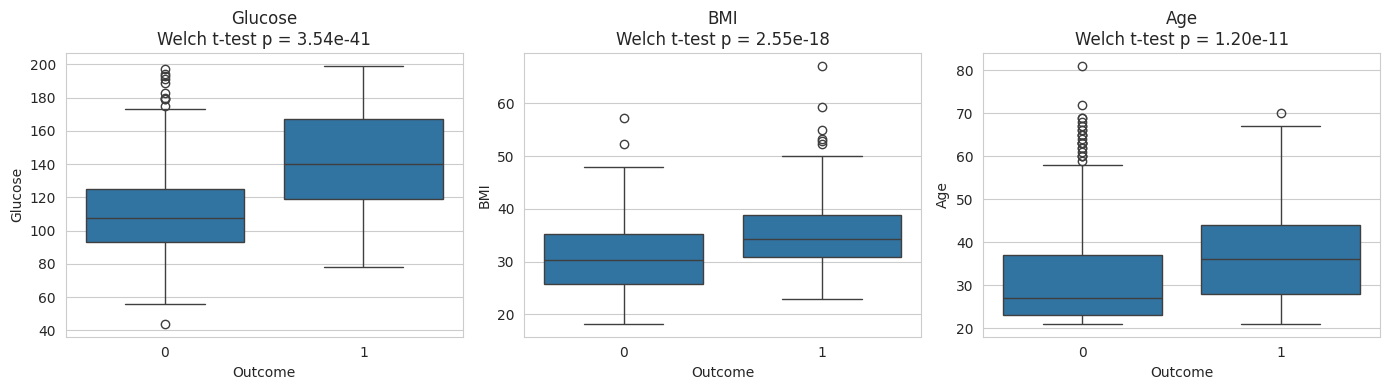

Inference: diabetic patients have a mean glucose of 142.1 mg/dL versus 110.7 mg/dL (p = 3.54e-41, Cohen's d = 1.19). We reject H0: glucose differs strongly between the groups.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, f in zip(axes, ["Glucose", "BMI", "Age"]):
    sns.boxplot(x="Outcome", y=f, data=pima_clean, ax=ax)
    ax.set_title(f"{f}\nWelch t-test p = {ttest_df.loc[f, 'p_value']:.2e}")
plt.tight_layout(); plt.show()

gl = ttest_df.loc["Glucose"]
print(f"Inference: diabetic patients have a mean glucose of {gl.mean_diabetic:.1f} mg/dL versus {gl.mean_healthy:.1f} mg/dL "
      f"(p = {gl.p_value:.2e}, Cohen's d = {gl.cohens_d:.2f}). We reject H0: glucose differs strongly between the groups.")

### (ii) Chi-square test of independence: is a categorical risk factor associated with diabetes?
We bin continuous variables into clinical categories and test each against `Outcome`.
- **H0:** the category and the outcome are independent. **H1:** they are associated.
- Cramér's V reports effect size (0 = none, 1 = perfect). The "expected count >= 5" rule is checked; WHO *Underweight*
  (only a handful of patients) is merged into *Normal* so the test stays valid.

In [ ]:
pima_clean["bmi_category"] = pd.cut(pima_clean["BMI"], bins=[0, 18.5, 25, 30, np.inf],
                                    labels=["Underweight", "Normal", "Overweight", "Obese"], right=False)
pima_clean["age_group"] = pd.cut(pima_clean["Age"], bins=[20, 30, 40, 50, 120],
                                 labels=["21-30", "31-40", "41-50", "51+"])
pima_clean["pregnancy_group"] = pd.cut(pima_clean["Pregnancies"], bins=[-1, 0, 3, 20],
                                       labels=["0", "1-3", "4+"])

def chi2_report(series, name):
    s = series.astype(str).replace({"Underweight": "Normal"}) if name == "bmi_category" else series.astype(str)
    table = pd.crosstab(s, pima_clean["Outcome"])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    n = table.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    return {"variable": name, "chi2": chi2, "dof": dof, "p_value": p, "cramers_V": cramers_v,
            "min_expected_count": expected.min(), "reject H0 (p<0.05)": p < 0.05}, table

results, tables = [], {}
for col in ["bmi_category", "age_group", "pregnancy_group"]:
    r, t = chi2_report(pima_clean[col], col)
    results.append(r); tables[col] = t

display(pd.DataFrame(results).set_index("variable").round(4))
print("Contingency table: BMI category vs Outcome")
display(tables["bmi_category"])

,chi2,dof,p_value,cramers_V,min_expected_count,reject H0 (p<0.05)
variable,,,,,,
bmi_category,74.8287,2,0.0,0.3121,36.9896,True
age_group,73.8089,3,0.0,0.3100,28.2656,True
pregnancy_group,32.1302,2,0.0,0.2045,38.7344,True


Contingency table: BMI category vs Outcome


Outcome,0,1
bmi_category,,
Normal,99,7
Obese,262,221
Overweight,139,40


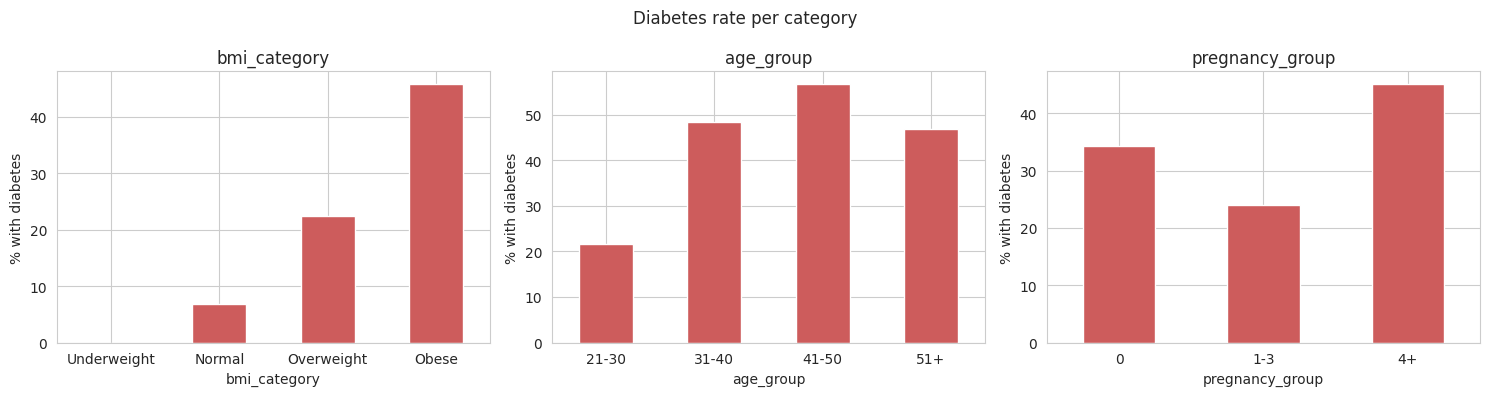

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["bmi_category", "age_group", "pregnancy_group"]):
    rate = pima_clean.groupby(col)["Outcome"].mean() * 100
    rate.plot(kind="bar", ax=ax, color="indianred"); ax.set_ylabel("% with diabetes"); ax.set_title(col)
    ax.tick_params(axis="x", rotation=0)
plt.suptitle("Diabetes rate per category"); plt.tight_layout(); plt.show()

## A5. Exploratory Data Analysis

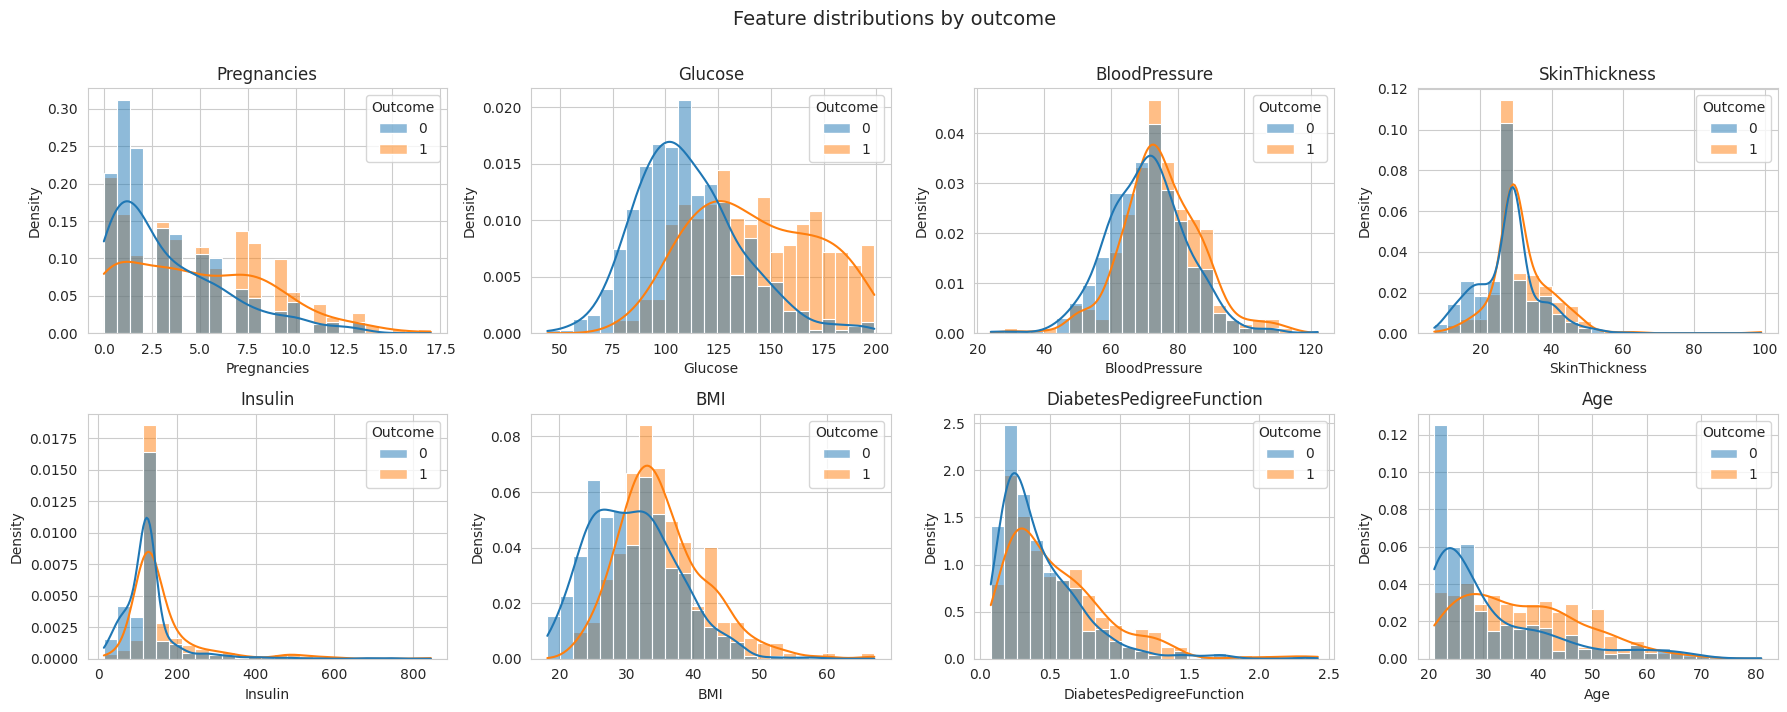

In [ ]:
# feature distributions split by outcome
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, f in zip(axes.ravel(), base_features):
    sns.histplot(data=pima_clean, x=f, hue="Outcome", kde=True, bins=25, stat="density", common_norm=False, ax=ax)
    ax.set_title(f)
plt.suptitle("Feature distributions by outcome", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

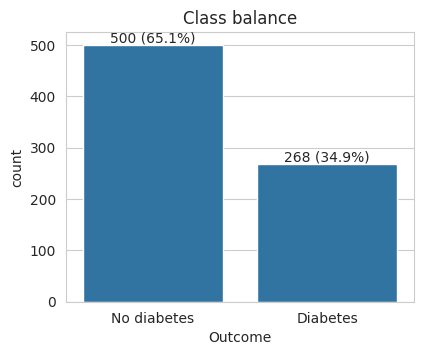

Imbalance ratio (majority:minority) = 1.87 : 1  -> moderate imbalance; use stratified splits and AUC/recall, not accuracy alone.


In [ ]:
# class balance
fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.countplot(x="Outcome", data=pima_clean, ax=ax)
tot = len(pima_clean)
for p_ in ax.patches:
    ax.annotate(f"{int(p_.get_height())} ({p_.get_height()/tot:.1%})", (p_.get_x() + p_.get_width()/2, p_.get_height()),
                ha="center", va="bottom")
ax.set_xticklabels(["No diabetes", "Diabetes"]); ax.set_title("Class balance")
plt.show()
counts = pima_clean["Outcome"].value_counts()
print(f"Imbalance ratio (majority:minority) = {counts.max()/counts.min():.2f} : 1  -> moderate imbalance; use stratified splits and AUC/recall, not accuracy alone.")

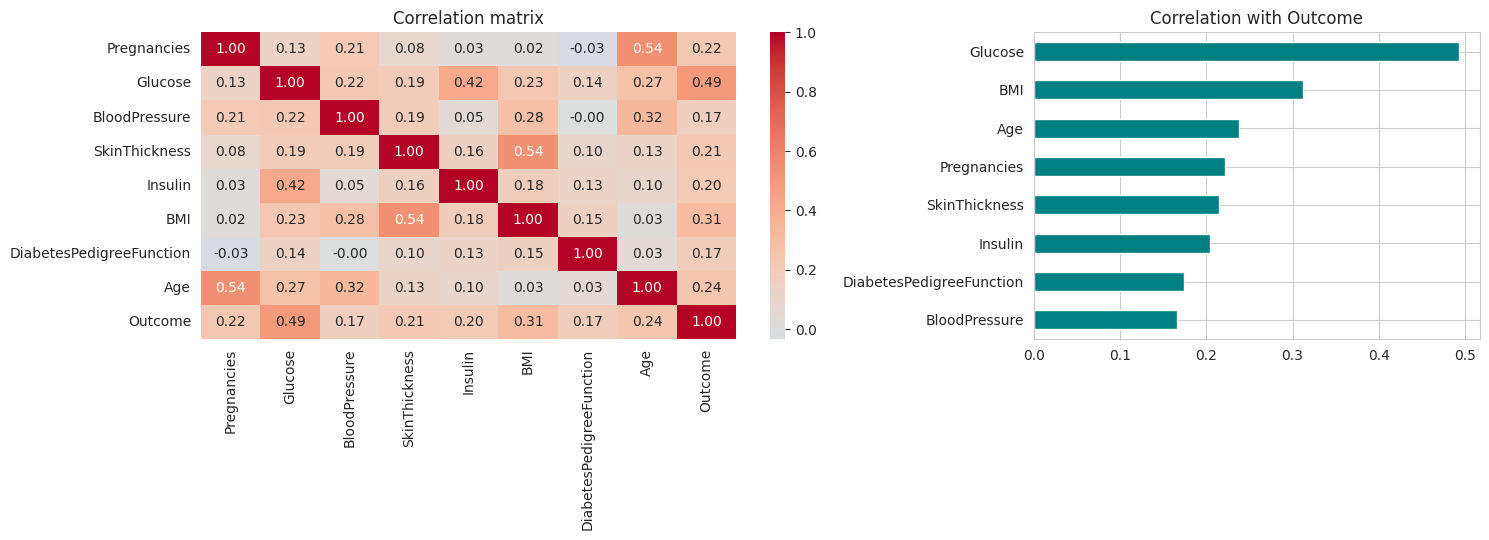

In [ ]:
# correlation heatmap + correlation with the outcome
corr = pima_clean[base_features + ["Outcome"]].corr()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Correlation matrix")
corr["Outcome"].drop("Outcome").sort_values().plot(kind="barh", ax=axes[1], color="teal")
axes[1].set_title("Correlation with Outcome")
plt.tight_layout(); plt.show()

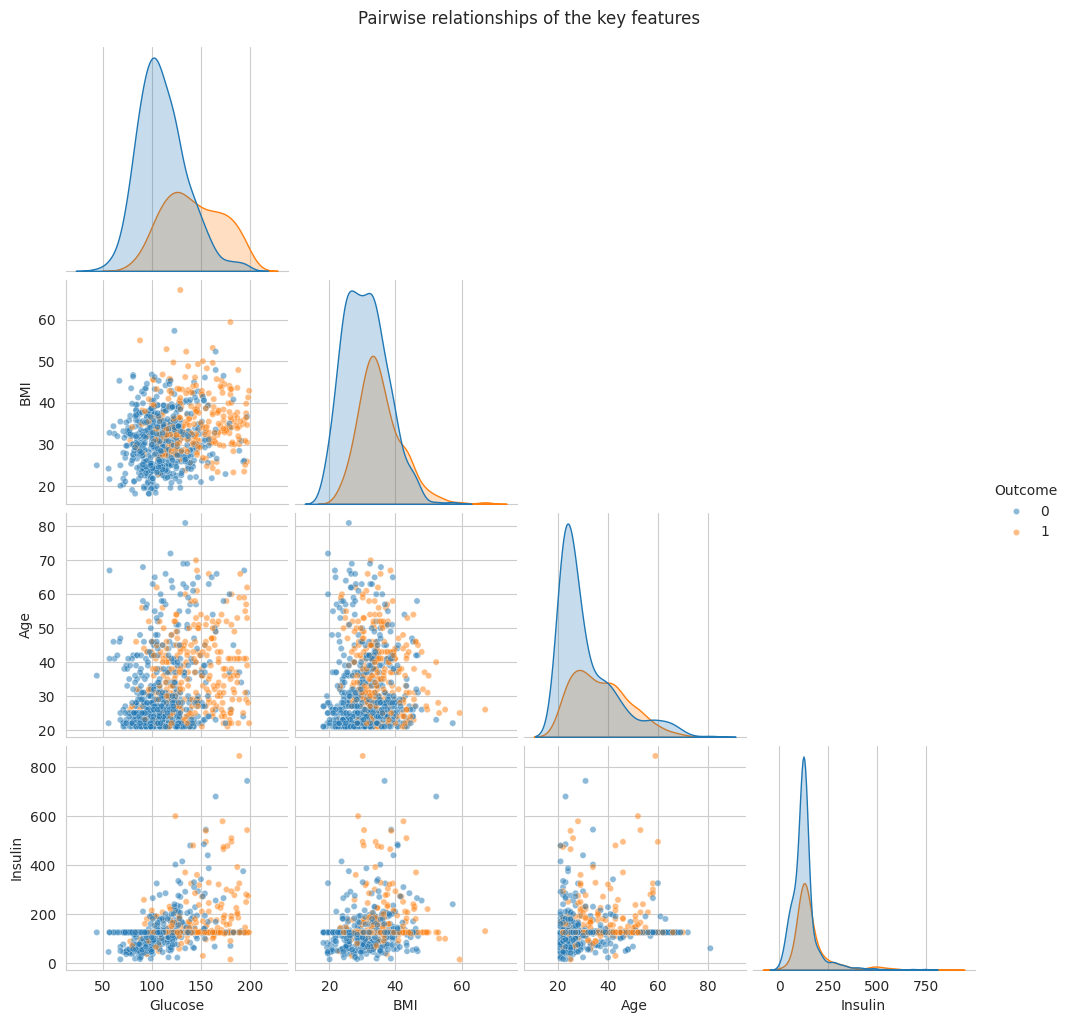

In [ ]:
sns.pairplot(pima_clean[["Glucose", "BMI", "Age", "Insulin", "Outcome"]], hue="Outcome", corner=True, plot_kws={"alpha": 0.5, "s": 20})
plt.suptitle("Pairwise relationships of the key features", y=1.02); plt.show()

## A6. Feature Engineering and Selection
**Derived clinical features** (`bmi_category`, `age_group` were created above for the chi-square test):

| Feature | Definition | Clinical meaning |
|---|---|---|
| `bmi_category` | WHO classes: <18.5, 18.5-25, 25-30, >=30 | obesity is a major diabetes risk |
| `glucose_category` | 2-h OGTT glucose: <140 normal, 140-199 prediabetes, >=200 diabetes range | American Diabetes Association cut-offs |
| `high_bp` | diastolic BP >= 90 mmHg | hypertension flag |
| `glucose_bmi` | `Glucose * BMI / 100` | interaction of the two strongest risk drivers |

In [ ]:
pima_clean["glucose_category"] = pd.cut(pima_clean["Glucose"], bins=[0, 140, 200, np.inf],
                                        labels=["Normal", "Prediabetes", "Diabetes-range"], right=False)
pima_clean["high_bp"] = (pima_clean["BloodPressure"] >= 90).astype(int)
pima_clean["glucose_bmi"] = pima_clean["Glucose"] * pima_clean["BMI"] / 100

cat_cols = ["bmi_category", "age_group", "glucose_category"]
dummies = pd.get_dummies(pima_clean[cat_cols].astype(str), dtype=int)

num_cols = base_features + ["Insulin_missing", "SkinThickness_missing", "high_bp", "glucose_bmi"]
cand = pd.concat([pima_clean[num_cols], dummies], axis=1)
y_all = pima_clean["Outcome"]
print("Candidate feature matrix:", cand.shape)
cand.head()

Candidate feature matrix: (768, 22)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Insulin_missing,SkinThickness_missing,high_bp,glucose_bmi,bmi_category_Normal,bmi_category_Obese,bmi_category_Overweight,bmi_category_Underweight,age_group_21-30,age_group_31-40,age_group_41-50,age_group_51+,glucose_category_Normal,glucose_category_Prediabetes
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1,0,0,49.728,0,1,0,0,0,0,1,0,0,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,1,0,0,22.610,0,0,1,0,0,1,0,0,1,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1,1,0,42.639,1,0,0,0,0,1,0,0,0,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0,0,0,25.009,0,0,1,0,1,0,0,0,1,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,0,0,0,59.047,0,1,0,0,0,1,0,0,1,0


### Feature selection: four independent methods, combined by average rank
1. **ANOVA F-test** (statistical, linear relationship with the outcome)
2. **Mutual information** (statistical, captures non-linear dependence)
3. **Random-forest importance** (model-based, tree ensemble)
4. **L1-regularised logistic regression** (model-based, shrinks useless coefficients to 0)

,anova_F,mutual_info,rf_importance,l1_abs_coef,mean_rank
glucose_bmi,283.750,0.135,0.165,0.523,1.250
Glucose,245.668,0.116,0.153,0.603,1.750
BMI,82.629,0.078,0.095,0.000,6.875
age_group_21-30,78.248,0.055,0.023,0.309,7.000
bmi_category_Obese,73.891,0.073,0.017,0.200,7.250
glucose_category_Normal,158.867,0.075,0.039,0.000,8.625
Pregnancies,39.670,0.027,0.059,0.140,8.750
glucose_category_Prediabetes,158.867,0.070,0.033,0.000,9.125
Age,46.141,0.041,0.085,0.000,9.375
DiabetesPedigreeFunction,23.871,0.013,0.092,0.180,10.250



Selected top 8 features: ['glucose_bmi', 'Glucose', 'BMI', 'age_group_21-30', 'bmi_category_Obese', 'glucose_category_Normal', 'Pregnancies', 'glucose_category_Prediabetes']


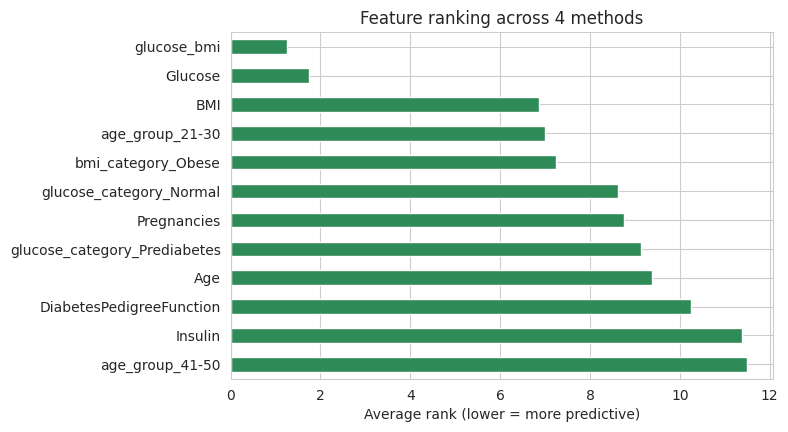

In [ ]:
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

f_score, f_p = f_classif(cand, y_all)
mi = mutual_info_classif(cand, y_all, random_state=RANDOM_STATE)
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1).fit(cand, y_all)
l1 = LogisticRegression(penalty="l1", solver="liblinear", C=0.1, random_state=RANDOM_STATE).fit(StandardScaler().fit_transform(cand), y_all)

scores = pd.DataFrame({"anova_F": f_score, "mutual_info": mi, "rf_importance": rf.feature_importances_,
                       "l1_abs_coef": np.abs(l1.coef_[0])}, index=cand.columns)
ranks = scores.rank(ascending=False)
scores["mean_rank"] = ranks.mean(axis=1)
scores = scores.sort_values("mean_rank")
display(scores.round(3))

TOP_K = 8
selected = scores.head(TOP_K).index.tolist()
print(f"\nSelected top {TOP_K} features:", selected)

scores.head(12)["mean_rank"].iloc[::-1].plot(kind="barh", figsize=(7, 4.5), color="seagreen")
plt.xlabel("Average rank (lower = more predictive)"); plt.title("Feature ranking across 4 methods"); plt.show()

In [ ]:
# does selection hurt? compare 5-fold CV ROC-AUC with scaling INSIDE each fold
from sklearn.pipeline import make_pipeline
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
feature_sets = {"Original 8": base_features, f"All {cand.shape[1]} candidates": list(cand.columns), f"Selected {TOP_K}": selected}
models = {"Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
          "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)}

res = {}
for fs_name, cols in feature_sets.items():
    for m_name, m in models.items():
        auc = cross_val_score(m, cand[cols], y_all, cv=cv, scoring="roc_auc")
        res[(fs_name, m_name)] = f"{auc.mean():.3f} +/- {auc.std():.3f}"
display(pd.Series(res).unstack().rename_axis("Feature set"))

,Logistic Regression,Random Forest
Feature set,,
All 22 candidates,0.845 +/- 0.014,0.832 +/- 0.027
Original 8,0.837 +/- 0.020,0.826 +/- 0.022
Selected 8,0.844 +/- 0.023,0.800 +/- 0.037


**Takeaway (Part A):** after treating hidden zeros as missing, glucose, BMI and age emerge as strong, statistically significant
risk markers, and the engineered `glucose_bmi` interaction ranks at the top. Compare the CV table above: feature selection mainly helps
the linear model and reduces dimensionality; tree ensembles can already ignore weak features, so the gain there is smaller or absent.
Insulin's high missingness means it should be interpreted cautiously.

---
# Part B: Textual Data (MTSamples Medical Transcriptions)
About 5,000 transcribed medical reports across 40 specialties. Columns: `description`, `medical_specialty`, `sample_name`,
`transcription`, `keywords`.

## B1. Data Acquisition and Analysis

In [ ]:
import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

def make_synthetic_mtsamples(seed=0, n_per=24):
    # SYNTHETIC stand-in used only if the real MTSamples file cannot be obtained.
    rnd = random.Random(seed)
    firsts = ["John", "Maria", "Robert", "Linda", "James", "Susan", "Ahmed", "Priya"]
    lasts = ["Smith", "Garcia", "Johnson", "Patel", "Brown", "Miller", "Davis", "Khan"]
    templates = {
        " Cardiology": "SUBJECTIVE:,  Mr. {l} is a {a}-year-old male with HTN, DM and CAD who presents with CP and SOB on exertion. MRN: {mrn}. Seen on {d}.<br>PAST MEDICAL HISTORY:,  Significant for CHF, MI in 2010 and COPD.  VITALS:,  BP 150/90, HR 88.  EKG shows ST depression. Echocardiogram reveals reduced ejection fraction. PLAN:,  Start aspirin, continue metoprolol, cardiac catheterization. Call {p}. Follow up with Dr. {l2}.",
        " Orthopedic": "PREOPERATIVE DIAGNOSIS:,  Right knee osteoarthritis.  PROCEDURE:,  Total knee arthroplasty.  Ms. {l} is a {a}-year-old female with chronic knee pain. Hx of fx of the tibia. The patient was taken to the operating room on {d}. Tourniquet applied, femoral and tibial components cemented. Wound closed with staples. Patient ID {mrn}. Surgeon: Dr. {l2}. Phone {p}.&nbsp;",
        " Gastroenterology": "HISTORY OF PRESENT ILLNESS:,  The patient is a {a}-year-old with GERD, abdominal pain, nausea and vomiting. Colonoscopy performed on {d} showed diverticulosis and internal hemorrhoids. Biopsy of the colon taken. ABDOMEN:,  Soft, nontender. Referred by Dr. {l2}. Medical Record Number: {mrn}.  Contact {p}.",
        " Neurology": "CHIEF COMPLAINT:,  Headache and dizziness.  Mrs. {l} is a {a}-year-old with migraine, seizure disorder and numbness of the left arm. MRI of the brain on {d} showed no acute infarct. Neurologic exam: cranial nerves intact, no focal deficit. EEG was normal. Started on topiramate. Dr. {l2} will follow. MRN {mrn}.",
        " Radiology": "EXAM:,  CT of the chest without contrast, {d}.  INDICATION:,  Cough and fever, rule out pneumonia in a {a}-year-old. FINDINGS:,  There is a right lower lobe consolidation consistent with pneumonia. No pleural effusion. No pneumothorax. The heart size is normal. IMPRESSION:,  Right lower lobe pneumonia. Dictated by Dr. {l2}. Accession {mrn}.",
    }
    rows = []
    for spec, tpl in templates.items():
        for _ in range(n_per):
            txt = tpl.format(l=rnd.choice(lasts), l2=rnd.choice(lasts), a=rnd.randint(25, 85),
                             mrn=rnd.randint(100000, 999999), d=f"{rnd.randint(1,12)}/{rnd.randint(1,28)}/{rnd.randint(2008,2020)}",
                             p=f"({rnd.randint(200,999)}) {rnd.randint(200,999)}-{rnd.randint(1000,9999)}")
            rows.append({"description": f"Sample {spec.strip()} report", "medical_specialty": spec,
                         "sample_name": f"{spec.strip()} note", "transcription": txt, "keywords": spec.lower()})
    df = pd.DataFrame(rows)
    df.loc[df.sample(4, random_state=1).index, "transcription"] = np.nan          # missing reports
    df.loc[df.sample(3, random_state=2).index, "transcription"] = "   "           # empty (whitespace) reports
    df = pd.concat([df, df.iloc[[10, 40]]], ignore_index=True)                   # exact duplicates
    return df

def get_mtsamples():
    if os.path.exists("mtsamples.csv"):
        return pd.read_csv("mtsamples.csv"), "local file mtsamples.csv"
    try:
        import kagglehub
        folder = kagglehub.dataset_download("tboyle10/medicaltranscriptions")
        return pd.read_csv(next(Path(folder).rglob("mtsamples.csv"))), "Kaggle (kagglehub)"
    except Exception as e:
        print("Kaggle download failed:", repr(e)[:160])
    try:
        from google.colab import files
        print("Please upload mtsamples.csv (or cancel to use the synthetic stand-in)...")
        up = files.upload()
        if up:
            name = [k for k in up if k.lower().endswith(".csv")][0]
            return pd.read_csv(name), "manual upload"
    except Exception:
        pass
    return make_synthetic_mtsamples(), "SYNTHETIC stand-in"

mt_raw, mt_src = get_mtsamples()
print(f"DATA SOURCE: {mt_src}" + ("   <-- NOT the real dataset" if "SYNTHETIC" in mt_src else ""))
print("Shape:", mt_raw.shape)
mt_raw.head(3)

Using Colab cache for faster access to the 'medicaltranscriptions' dataset.
DATA SOURCE: Kaggle (kagglehub)
Shape: (4999, 6)


,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."


In [ ]:
mt = mt_raw.copy()
mt = mt.drop(columns=[c for c in mt.columns if c.startswith("Unnamed")])
mt["medical_specialty"] = mt["medical_specialty"].astype(str).str.strip()

print("Missing values per column:")
display(mt.isnull().sum().to_frame("missing").T)

# empty reports = NaN or whitespace-only
is_empty = mt["transcription"].isna() | mt["transcription"].astype(str).str.strip().eq("") | mt["transcription"].astype(str).str.lower().eq("nan")
print(f"\nMissing / empty transcriptions: {int(is_empty.sum())} of {len(mt)}")

mt = mt[~is_empty].copy()
n_dup = int(mt.duplicated(subset="transcription").sum())
mt = mt.drop_duplicates(subset="transcription").reset_index(drop=True)
print(f"Duplicate transcriptions removed: {n_dup}  ->  {len(mt)} reports remain")

Missing values per column:


,description,medical_specialty,sample_name,transcription,keywords
missing,0,0,0,33,1068



Missing / empty transcriptions: 33 of 4999
Duplicate transcriptions removed: 2609  ->  2357 reports remain


Specialties: 39


,count,mean,std,min,25%,50%,75%,max
n_chars,2357.0,3005.4,1987.1,11.0,1570.0,2613.0,3950.0,18425.0
n_words,2357.0,458.3,315.2,1.0,237.0,389.0,608.0,3029.0


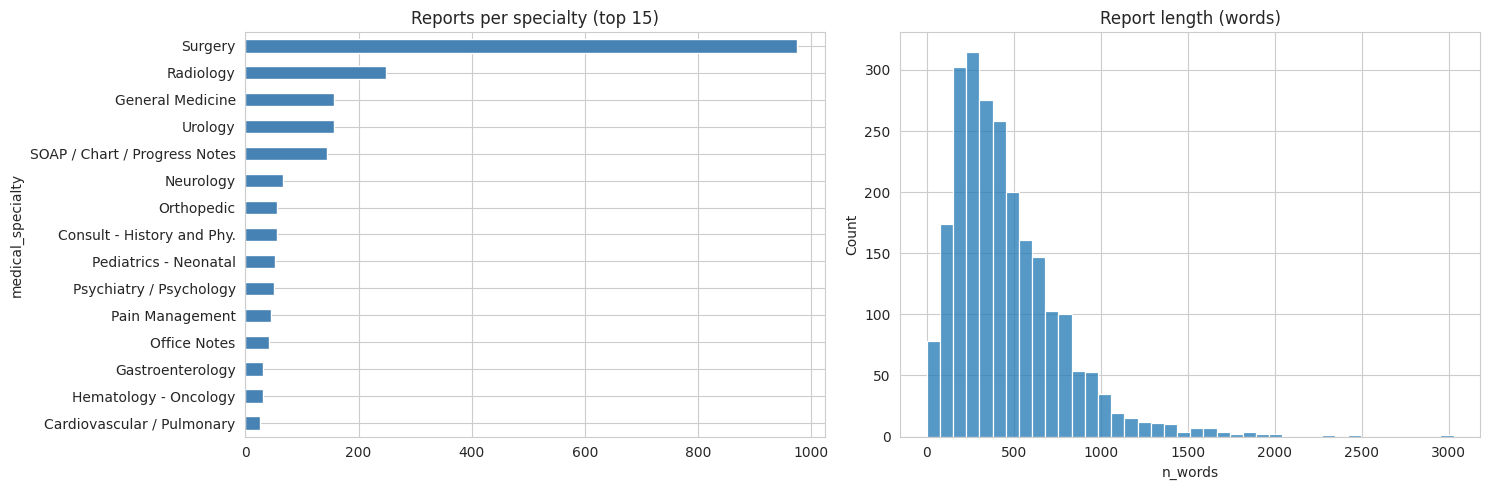

Sample transcription:
 SUBJECTIVE:,  This 23-year-old white female presents with complaint of allergies.  She used to have allergies when she lived in Seattle but she thinks they are worse here.  In the past, she has tried Claritin, and Zyrtec.  Both worked for short time but then seemed to lose effectiveness.  She has used Allegra also.  She used that last summer and she began using it again two weeks ago.  It does not appear to be working very well.  She has used over-the-counter sprays but no prescription nasal sprays.  She does have asthma but doest not require daily medication for this and does not think it is 


In [ ]:
mt["n_chars"] = mt["transcription"].str.len()
mt["n_words"] = mt["transcription"].str.split().str.len()
print(f"Specialties: {mt['medical_specialty'].nunique()}")
display(mt[["n_chars", "n_words"]].describe().round(1).T)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top = mt["medical_specialty"].value_counts().head(15)
top.iloc[::-1].plot(kind="barh", ax=axes[0], color="steelblue"); axes[0].set_title("Reports per specialty (top 15)")
sns.histplot(mt["n_words"], bins=40, ax=axes[1]); axes[1].set_title("Report length (words)")
plt.tight_layout(); plt.show()

print("Sample transcription:\n", mt["transcription"].iloc[0][:600])

## B2. De-identification / PHI Check
Regular expressions scan for the HIPAA identifiers that can appear in free text: **names** (title + surname or "Patient Name:"),
**dates**, **MRN / account numbers**, **phone numbers**, plus SSNs and e-mail addresses. Each hit is replaced with a typed placeholder
such as `[PHONE]`. Regex-based scrubbing is a first line of defence, not a guarantee: production systems add NER-based de-identification and manual audit.

In [ ]:
MONTHS = r"(?:Jan(?:uary)?|Feb(?:ruary)?|Mar(?:ch)?|Apr(?:il)?|May|Jun(?:e)?|Jul(?:y)?|Aug(?:ust)?|Sep(?:t(?:ember)?)?|Oct(?:ober)?|Nov(?:ember)?|Dec(?:ember)?)"

PHI_PATTERNS = {
    "EMAIL": re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b"),
    "SSN":   re.compile(r"\b\d{3}-\d{2}-\d{4}\b"),
    "PHONE": re.compile(r"(?<!\d)(?:\+?1[-.\s]?)?\(?\d{3}\)?[-.\s]\d{3}[-.\s]\d{4}(?!\d)"),
    "MRN":   re.compile(r"\b(?:MRN|MR\s?#|Medical Record (?:Number|No\.?|#)|Chart (?:Number|No\.?|#)|Account (?:Number|No\.?|#)|Patient ID|Accession)\s*[:#]?\s*[A-Z]*\d[\d-]{3,}\b", re.I),
    "DATE":  re.compile(r"\b(?:0?[1-9]|1[0-2])[/-](?:0?[1-9]|[12]\d|3[01])[/-](?:\d{4}|\d{2})\b"
                        r"|\b\d{4}-\d{2}-\d{2}\b"
                        r"|\b" + MONTHS + r"\.?\s+\d{1,2}(?:st|nd|rd|th)?(?:,\s*|\s+)\d{4}\b"),
    "NAME":  re.compile(r"\b(?:Dr|Mr|Mrs|Ms|Miss)\.?\s+[A-Z][a-z]+(?:\s+[A-Z][a-z]+)?"
                        r"|\b(?:Patient Name|PATIENT NAME|Name|NAME)\s*:\s*[A-Z][a-z]+(?:\s+[A-Z][a-z]+){0,2}"),
}

def scan_phi(text):
    return {label: len(rx.findall(text)) for label, rx in PHI_PATTERNS.items()}

def redact_phi(text):
    for label, rx in PHI_PATTERNS.items():
        text = rx.sub(f"[{label}]", text)
    return text

# unit test on a made-up note
demo = ("Patient Name: John Smith, MRN: 4839201, seen on 03/14/2019 by Dr. Patel. "
        "Call (555) 123-4567 or john.smith@mail.com. SSN 123-45-6789. BP was 140/90.")
print("BEFORE:", demo)
print("AFTER :", redact_phi(demo))

BEFORE: Patient Name: John Smith, MRN: 4839201, seen on 03/14/2019 by Dr. Patel. Call (555) 123-4567 or john.smith@mail.com. SSN 123-45-6789. BP was 140/90.
AFTER : [NAME], [MRN], seen on [DATE] by [NAME]. Call [PHONE] or [EMAIL]. SSN [SSN]. BP was 140/90.


In [ ]:
# scan the whole corpus
phi_hits = mt["transcription"].apply(scan_phi).apply(pd.Series)
phi_summary = pd.DataFrame({"total_matches": phi_hits.sum(), "reports_affected": (phi_hits > 0).sum()})
phi_summary["reports_affected_%"] = (phi_summary["reports_affected"] / len(mt) * 100).round(1)
display(phi_summary)

# redact and verify nothing is left
mt["text_redacted"] = mt["transcription"].apply(redact_phi)
residual = mt["text_redacted"].apply(scan_phi).apply(pd.Series)
print(f"\nResidual PHI matches after redaction (re-scan of the redacted text): {int(residual.sum().sum())}")

# show one before / after
i = int(phi_hits.sum(axis=1).idxmax())
print("\nORIGINAL :", mt.loc[i, "transcription"][:420])
print("\nREDACTED :", mt.loc[i, "text_redacted"][:420])

,total_matches,reports_affected,reports_affected_%
EMAIL,0,0,0.0
SSN,0,0,0.0
PHONE,1,1,0.0
MRN,1,1,0.0
DATE,1272,454,19.3
NAME,186,89,3.8



Residual PHI matches after redaction (re-scan of the redacted text): 0

ORIGINAL : DATE OF INJURY : October 4, 2000,DATE OF EXAMINATION : September 5, 2003,EXAMINING PHYSICIAN : X Y, MD,Prior to the beginning of the examination, it is explained to the examinee that this examination is intended for evaluative purposes only, and that it is not intended to constitute a general medical examination. It is explained to the examinee that the traditional doctor-patient relationship does not apply to this e

REDACTED : DATE OF INJURY : [DATE],DATE OF EXAMINATION : [DATE],EXAMINING PHYSICIAN : X Y, MD,Prior to the beginning of the examination, it is explained to the examinee that this examination is intended for evaluative purposes only, and that it is not intended to constitute a general medical examination. It is explained to the examinee that the traditional doctor-patient relationship does not apply to this examination, and that


## B3. Text Cleaning
Order matters: PHI is redacted first (needs capitalisation and punctuation), then HTML artefacts and **section headers**
(upper-case labels such as `PAST MEDICAL HISTORY:,`) are removed while case is still available, and only then do we lower-case,
strip non-alphanumeric characters and collapse whitespace.

In [ ]:
HTML_TAG = re.compile(r"<[^>]+>")
HEADER = re.compile(r"\b[A-Z][A-Z /&\-]{4,60}:,?")
PLACEHOLDER = re.compile(r"\[(?:NAME|DATE|PHONE|MRN|SSN|EMAIL)\]")

def clean_text(t):
    t = html.unescape(t)
    t = HTML_TAG.sub(" ", t)             # HTML artefacts (<br>, &nbsp; ...)
    t = HEADER.sub(" ", t)               # section header noise
    t = PLACEHOLDER.sub(" ", t)          # PHI placeholders carry no clinical meaning
    t = t.lower()
    t = re.sub(r"[^a-z0-9\s]", " ", t)   # keep only letters, digits, spaces
    return re.sub(r"\s+", " ", t).strip()

mt["text_clean"] = mt["text_redacted"].apply(clean_text)

print("REDACTED:", mt["text_redacted"].iloc[0][:350])
print("\nCLEANED :", mt["text_clean"].iloc[0][:350])
print(f"\nAverage length: {mt['text_redacted'].str.len().mean():.0f} -> {mt['text_clean'].str.len().mean():.0f} characters")

REDACTED: SUBJECTIVE:,  This 23-year-old white female presents with complaint of allergies.  She used to have allergies when she lived in Seattle but she thinks they are worse here.  In the past, she has tried Claritin, and Zyrtec.  Both worked for short time but then seemed to lose effectiveness.  She has used Allegra also.  She used that last summer and sh

CLEANED : this 23 year old white female presents with complaint of allergies she used to have allergies when she lived in seattle but she thinks they are worse here in the past she has tried claritin and zyrtec both worked for short time but then seemed to lose effectiveness she has used allegra also she used that last summer and she began using it again two

Average length: 3003 -> 2765 characters


## B4. Tokenization and Stop-word Removal
NLTK's English stop-word list is used, **minus the negations** `no`, `nor`, `not`: in clinical text "no pneumothorax" and
"pneumothorax" mean opposite things, so negations are kept.

In [ ]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english")) - {"no", "nor", "not"}

def tokenize(text):
    return word_tokenize(text)

def remove_stopwords(tokens):
    return [t for t in tokens if t not in STOP and len(t) > 1 and not t.isdigit()]

mt["tokens"] = mt["text_clean"].apply(tokenize)
mt["tokens_nostop"] = mt["tokens"].apply(remove_stopwords)

print("Tokens (first 25)        :", mt["tokens"].iloc[0][:25])
print("After stop-word removal  :", mt["tokens_nostop"].iloc[0][:25])
print(f"\nMean tokens per report: {mt['tokens'].str.len().mean():.0f} -> {mt['tokens_nostop'].str.len().mean():.0f}")

Tokens (first 25)        : ['this', '23', 'year', 'old', 'white', 'female', 'presents', 'with', 'complaint', 'of', 'allergies', 'she', 'used', 'to', 'have', 'allergies', 'when', 'she', 'lived', 'in', 'seattle', 'but', 'she', 'thinks', 'they']
After stop-word removal  : ['year', 'old', 'white', 'female', 'presents', 'complaint', 'allergies', 'used', 'allergies', 'lived', 'seattle', 'thinks', 'worse', 'past', 'tried', 'claritin', 'zyrtec', 'worked', 'short', 'time', 'seemed', 'lose', 'effectiveness', 'used', 'allegra']

Mean tokens per report: 464 -> 262


## B5. Normalization: Abbreviation Expansion and Lemmatization
Common clinical abbreviations are expanded to full terms (so `htn` and `hypertension` map to the same feature), the stop-word
filter is applied again to expanded phrases (e.g. the "of" in *shortness of breath*), and tokens are lemmatized
(`diagnosed -> diagnose`, `lungs -> lung`). Ambiguous abbreviations (e.g. `pt` = patient or physical therapy) use the most common reading.

In [ ]:
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()

ABBREV = {
    "bp": "blood pressure", "hr": "heart rate", "rr": "respiratory rate", "hx": "history", "pt": "patient",
    "htn": "hypertension", "dm": "diabetes mellitus", "cad": "coronary artery disease", "chf": "congestive heart failure",
    "copd": "chronic obstructive pulmonary disease", "mi": "myocardial infarction", "sob": "shortness of breath",
    "cp": "chest pain", "uti": "urinary tract infection", "gerd": "gastroesophageal reflux disease",
    "ekg": "electrocardiogram", "ecg": "electrocardiogram", "ct": "computed tomography",
    "mri": "magnetic resonance imaging", "eeg": "electroencephalogram", "iv": "intravenous", "po": "by mouth",
    "prn": "as needed", "bid": "twice daily", "tid": "three times daily", "qid": "four times daily",
    "dx": "diagnosis", "tx": "treatment", "sx": "symptoms", "rx": "prescription", "fx": "fracture",
    "wnl": "within normal limits", "nad": "no acute distress", "hpi": "history of present illness",
    "ros": "review of systems", "abd": "abdomen", "lle": "left lower extremity", "rle": "right lower extremity",
    "cbc": "complete blood count", "ua": "urinalysis", "er": "emergency room", "or": "operating room",
}

def expand_abbrev(tokens):
    out = []
    for t in tokens:
        out.extend(ABBREV[t].split() if t in ABBREV and t != "or" else [t])   # 'or' is also an English word -> skip
    return out

def lemmatize(tokens):
    return [lemmatizer.lemmatize(lemmatizer.lemmatize(t, pos="v"), pos="n") for t in tokens]

def normalize(tokens):
    return lemmatize(remove_stopwords(expand_abbrev(tokens)))

mt["tokens_norm"] = mt["tokens_nostop"].apply(normalize)
mt["text_final"] = mt["tokens_norm"].apply(" ".join)

ex = mt["tokens_nostop"].iloc[0]
print("Before:", ex[:20]); print("After :", normalize(ex)[:20])
print("\nExpansion demo:", expand_abbrev(["pt", "htn", "dm", "sob", "wnl"]))
print("Lemma demo    :", lemmatize(["lungs", "diagnosed", "presenting", "infections"]))
print(f"\nVocabulary size: {len(set(t for ts in mt['tokens_nostop'] for t in ts)):,} -> {len(set(t for ts in mt['tokens_norm'] for t in ts)):,}")

Before: ['year', 'old', 'white', 'female', 'presents', 'complaint', 'allergies', 'used', 'allergies', 'lived', 'seattle', 'thinks', 'worse', 'past', 'tried', 'claritin', 'zyrtec', 'worked', 'short', 'time']
After : ['year', 'old', 'white', 'female', 'present', 'complaint', 'allergy', 'use', 'allergy', 'live', 'seattle', 'think', 'worse', 'past', 'try', 'claritin', 'zyrtec', 'work', 'short', 'time']

Expansion demo: ['patient', 'hypertension', 'diabetes', 'mellitus', 'shortness', 'of', 'breath', 'within', 'normal', 'limits']
Lemma demo    : ['lung', 'diagnose', 'present', 'infection']

Vocabulary size: 21,426 -> 17,163


## B6. Feature Extraction with TF-IDF
TF-IDF weights a term by how often it appears in a report **and** how rare it is across all reports, so distinctive clinical
terms (`arthroplasty`, `consolidation`) score higher than words found everywhere. Uni- and bi-grams are used;
`min_df` drops very rare terms and `max_df` drops near-universal ones.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=3, max_df=0.8, sublinear_tf=True)
X_tfidf = tfidf.fit_transform(mt["text_final"])
terms = np.array(tfidf.get_feature_names_out())

print("TF-IDF matrix shape:", X_tfidf.shape, "(reports x terms)")
print(f"Sparsity: {(1 - X_tfidf.nnz / np.prod(X_tfidf.shape)):.2%} zeros")

global_top = np.asarray(X_tfidf.sum(axis=0)).ravel().argsort()[::-1][:15]
print("\nTop 15 terms overall:", list(terms[global_top]))

TF-IDF matrix shape: (2357, 5000) (reports x terms)
Sparsity: 96.48% zeros

Top 15 terms overall: ['no', 'right', 'leave', 'normal', 'use', 'place', 'not', 'well', 'pain', 'procedure', 'time', 'note', 'history', 'year', 'take']


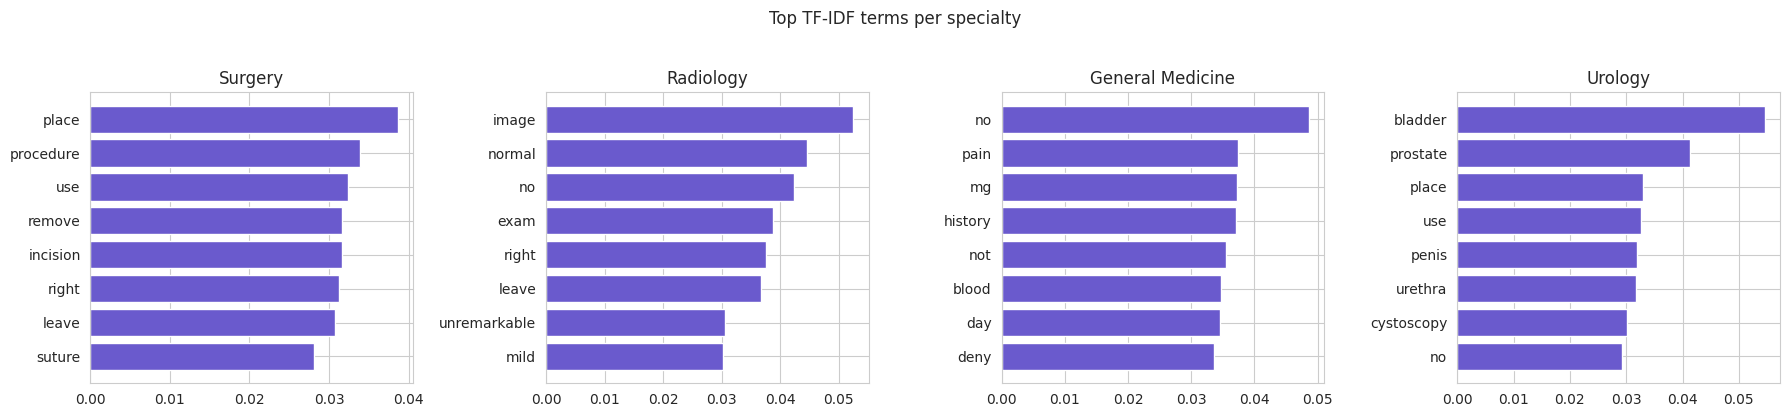

In [ ]:
# most distinctive terms for the 4 biggest specialties
top_specs = mt["medical_specialty"].value_counts().head(4).index
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, spec in zip(axes, top_specs):
    idx = np.where(mt["medical_specialty"].values == spec)[0]
    mean_vec = np.asarray(X_tfidf[idx].mean(axis=0)).ravel()
    top = mean_vec.argsort()[::-1][:8]
    ax.barh(terms[top][::-1], mean_vec[top][::-1], color="slateblue"); ax.set_title(spec.strip())
plt.suptitle("Top TF-IDF terms per specialty", y=1.03); plt.tight_layout(); plt.show()

In [ ]:
# sanity check: do the features carry signal? classify the 5 largest specialties
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

keep = mt["medical_specialty"].isin(mt["medical_specialty"].value_counts().head(5).index).values
Xtr, Xte, ytr, yte = train_test_split(X_tfidf[keep], mt.loc[keep, "medical_specialty"], test_size=0.25,
                                      stratify=mt.loc[keep, "medical_specialty"], random_state=RANDOM_STATE)
clf = LogisticRegression(max_iter=2000).fit(Xtr, ytr)
print(f"Specialty classification accuracy from TF-IDF features: {accuracy_score(yte, clf.predict(Xte)):.3f}")

Specialty classification accuracy from TF-IDF features: 0.893


**Takeaway (Part B):** free-text reports contain residual identifiers that must be redacted *before* any modelling; cleaning
and normalization shrink the vocabulary, and the TF-IDF matrix (sparse, model-ready) separates specialties well.

---
# Part C: Image Data (Chest X-Ray, Pneumonia)
Paediatric chest X-rays (JPEG) in the folder layout `chest_xray/{train,val,test}/{NORMAL,PNEUMONIA}/`.

## C1. Data Acquisition and Inspection

In [ ]:
from PIL import Image, ImageOps, ImageEnhance, ImageDraw, ImageFilter

def find_xray_root(base):
    base = Path(base)
    if (base / "train").is_dir() and (base / "test").is_dir():
        return base
    for tr in base.rglob("train"):
        if tr.is_dir() and (tr.parent / "test").is_dir():
            return tr.parent
    return None

def make_synthetic_xray(root="synthetic_chest_xray", seed=0):
    # SYNTHETIC stand-in (lung-like ellipses + noise). Includes deliberate defects so Section C3 has something to catch.
    rng = np.random.default_rng(seed); root = Path(root)
    spec = {"train": {"NORMAL": 60, "PNEUMONIA": 180}, "val": {"NORMAL": 8, "PNEUMONIA": 8}, "test": {"NORMAL": 30, "PNEUMONIA": 50}}
    def make_img(pneu):
        w, h = int(rng.integers(300, 420)), int(rng.integers(280, 400))
        im = Image.new("L", (w, h), int(rng.integers(15, 40))); d = ImageDraw.Draw(im)
        j = lambda: float(rng.uniform(-0.07, 0.07))                    # anatomical variation between "patients"
        d.ellipse([w*(.12+j()), h*(.15+j()), w*(.46+j()), h*(.85+j())], fill=int(rng.integers(90, 130)))
        d.ellipse([w*(.54+j()), h*(.15+j()), w*(.88+j()), h*(.85+j())], fill=int(rng.integers(90, 130)))
        d.rectangle([w*(.46+j()/2), h*.05, w*(.54+j()/2), h*.95], fill=int(rng.integers(160, 215)))
        if pneu:
            for _ in range(int(rng.integers(2, 5))):
                x, y, r = rng.integers(int(w*.15), int(w*.8)), rng.integers(int(h*.25), int(h*.75)), rng.integers(20, 45)
                d.ellipse([x-r, y-r, x+r, y+r], fill=int(rng.integers(170, 220)))
        im = im.filter(ImageFilter.GaussianBlur(float(rng.uniform(3, 6))))
        tex = Image.fromarray(rng.integers(0, 255, (h, w), dtype=np.uint8)).filter(ImageFilter.GaussianBlur(12))
        tex = np.asarray(tex, dtype=np.float32); tex = (tex - tex.mean()) / (tex.std() + 1e-6)   # smooth random "tissue" texture
        arr = np.asarray(im, dtype=np.float32) + 30 * tex + rng.normal(0, 6, (h, w))
        return Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))
    made = {}
    for sp, d in spec.items():
        for lab, n in d.items():
            (root / sp / lab).mkdir(parents=True, exist_ok=True)
            for i in range(n):
                p = root / sp / lab / f"IM-{sp}-{lab[:3]}-{i:04d}.jpeg"
                make_img(lab == "PNEUMONIA").save(p, quality=90); made[(sp, lab, i)] = p
    # --- deliberate defects
    (root/"train"/"NORMAL"/"IM-corrupt-0001.jpeg").write_bytes(os.urandom(2048))              # corrupted
    (root/"train"/"NORMAL"/"IM-corrupt-0002.jpeg").write_bytes(b"\xff\xd8\xff\xe0" + os.urandom(300))   # truncated
    Image.new("L", (320, 300), 0).save(root/"train"/"PNEUMONIA"/"IM-blank-0001.jpeg")          # blank image
    for k in range(4):                                                                         # near-duplicates inside train
        src = made[("train", "PNEUMONIA", k)]
        arr = np.asarray(Image.open(src), dtype=np.float32) + rng.normal(0, 1.0, np.asarray(Image.open(src)).shape)
        Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8)).save(root/"train"/"PNEUMONIA"/f"IM-dup-{k:04d}.jpeg", quality=88)
    for k in range(2):                                                                         # train/test leakage
        Image.open(made[("test", "NORMAL", k)]).save(root/"train"/"NORMAL"/f"IM-leak-{k:04d}.jpeg", quality=85)
    return root

XRAY_ROOT, xray_src = None, None
if os.path.isdir("chest_xray"):
    XRAY_ROOT, xray_src = find_xray_root("chest_xray"), "local folder chest_xray"
if XRAY_ROOT is None:
    try:
        import kagglehub
        XRAY_ROOT = find_xray_root(kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia"))
        xray_src = "Kaggle (kagglehub)"
    except Exception as e:
        print("Kaggle download failed:", repr(e)[:160])
if XRAY_ROOT is None:
    XRAY_ROOT, xray_src = make_synthetic_xray(), "SYNTHETIC stand-in"

print(f"DATA SOURCE: {xray_src}" + ("   <-- NOT the real dataset" if "SYNTHETIC" in xray_src else ""))
print("Root folder:", XRAY_ROOT)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
DATA SOURCE: Kaggle (kagglehub)
Root folder: /kaggle/input/chest-xray-pneumonia/chest_xray


In [ ]:
IMG_EXT = {".jpeg", ".jpg", ".png", ".dcm", ".tif", ".tiff"}
rows = []
for p in Path(XRAY_ROOT).rglob("*"):
    if p.is_file() and p.suffix.lower() in IMG_EXT and "__MACOSX" not in p.parts and not p.name.startswith("._"):
        split, label = p.parent.parent.name.lower(), p.parent.name.upper()
        if split in {"train", "val", "test"} and label in {"NORMAL", "PNEUMONIA"}:
            rows.append({"path": str(p), "split": split, "label": label, "ext": p.suffix.lower()})
files_df = pd.DataFrame(rows).sort_values("path").reset_index(drop=True)

print(f"Total image files: {len(files_df)}\n")
print("Images per split x class:")
display(pd.crosstab(files_df["split"], files_df["label"], margins=True))
print("File formats:", files_df["ext"].value_counts().to_dict())

Total image files: 11712

Images per split x class:


label,NORMAL,PNEUMONIA,All
split,,,
test,468,780,1248
train,2682,7750,10432
val,16,16,32
All,3166,8546,11712


File formats: {'.jpeg': 11712}


In [ ]:
def header_info(p):
    try:
        with Image.open(p) as im:
            return im.width, im.height, im.mode, im.format
    except Exception:
        return None, None, None, None

info = [header_info(p) for p in tqdm(files_df["path"], desc="reading headers")]
files_df[["width", "height", "mode", "format"]] = pd.DataFrame(info, index=files_df.index)

print("Unreadable headers:", int(files_df["width"].isna().sum()))
print("Colour modes :", files_df["mode"].value_counts(dropna=False).to_dict())
print("Formats      :", files_df["format"].value_counts(dropna=False).to_dict())
display(files_df[["width", "height"]].describe().round(0).T)
print(f"Distinct image sizes: {files_df[['width','height']].drop_duplicates().shape[0]} -> images must be resized to a common shape.")

reading headers:   0%|          | 0/11712 [00:00<?, ?it/s]

Unreadable headers: 0
Colour modes : {'L': 11146, 'RGB': 566}
Formats      : {'JPEG': 11712}


,count,mean,std,min,25%,50%,75%,max
width,11712.0,1328.0,363.0,384.0,1056.0,1281.0,1560.0,2916.0
height,11712.0,971.0,383.0,127.0,688.0,888.0,1187.0,2713.0


Distinct image sizes: 4803 -> images must be resized to a common shape.


## C2. Metadata Handling and Anonymization
**DICOM** headers can hold patient name, ID, birth date, institution, physician names and private vendor tags. They must be
stripped *before* any further processing. The Kaggle X-rays are already JPEG (no DICOM header), so we
1. demonstrate the anonymizer on a real DICOM file that ships with `pydicom`, and
2. check the JPEGs for embedded metadata (EXIF) and show that our pipeline reads **pixels only**.

In [ ]:
import copy, pydicom
from pydicom.data import get_testdata_file

PHI_KEYWORDS = ["PatientName", "PatientID", "PatientBirthDate", "PatientBirthTime", "OtherPatientIDs", "OtherPatientNames",
                "PatientAddress", "PatientTelephoneNumbers", "PatientMotherBirthName", "InstitutionName", "InstitutionAddress",
                "ReferringPhysicianName", "PerformingPhysicianName", "PhysiciansOfRecord", "OperatorsName",
                "AccessionNumber", "StudyID", "StationName", "DeviceSerialNumber",
                "StudyDate", "SeriesDate", "AcquisitionDate", "ContentDate", "StudyTime", "SeriesTime", "AcquisitionTime", "ContentTime"]

def anonymize_dicom(ds):
    ds = copy.deepcopy(ds)
    for kw in PHI_KEYWORDS:
        if kw in ds:
            ds.data_element(kw).value = "ANONYMOUS" if kw in ("PatientName", "PatientID") else ""
    ds.remove_private_tags()                       # vendor-specific tags may hide identifiers
    ds.PatientIdentityRemoved = "YES"
    ds.DeidentificationMethod = "Lab 3 basic profile (tag blanking + private tag removal)"
    return ds

ds = pydicom.dcmread(get_testdata_file("CT_small.dcm"))
ds_anon = anonymize_dicom(ds)

report = pd.DataFrame({"BEFORE": [str(ds.get(k, "-")) for k in PHI_KEYWORDS],
                       "AFTER": [str(ds_anon.get(k, "-")) for k in PHI_KEYWORDS]}, index=PHI_KEYWORDS)
display(report[(report["BEFORE"] != "-") | (report["AFTER"] != "-")])
print("Private tags before/after:", sum(1 for e in ds if e.tag.is_private), "/", sum(1 for e in ds_anon if e.tag.is_private))
print("Pixel data unchanged:", np.array_equal(ds.pixel_array, ds_anon.pixel_array))

,BEFORE,AFTER
PatientName,CompressedSamples^CT1,ANONYMOUS
PatientID,1CT1,ANONYMOUS
PatientBirthDate,,
InstitutionName,JFK IMAGING CENTER,
ReferringPhysicianName,,
AccessionNumber,,
StudyID,1CT1,
StationName,CT01_OC0,
StudyDate,20040119,
SeriesDate,19970430,


Private tags before/after: 179 / 0
Pixel data unchanged: True


In [ ]:
# JPEG metadata check: EXIF / text chunks can carry device and patient information
sample_paths = files_df["path"].sample(min(200, len(files_df)), random_state=RANDOM_STATE)
with_meta = 0
for p in sample_paths:
    try:
        with Image.open(p) as im:
            if len(im.getexif()) > 0 or any(k not in {"jfif", "jfif_version", "dpi", "jfif_unit", "jfif_density", "progressive", "progression"} for k in im.info):
                with_meta += 1
    except Exception:
        pass
print(f"Images with embedded metadata in a random sample of {len(sample_paths)}: {with_meta}")

def strip_metadata_copy(src, dst):
    # re-encode pixels only; EXIF / comments are not carried over
    with Image.open(src) as im:
        clean = Image.new(im.mode, im.size); clean.putdata(list(im.getdata())); clean.save(dst)

strip_metadata_copy(sample_paths.iloc[0], "anonymized_sample.png")
print("Saved metadata-free copy: anonymized_sample.png  (all later steps use pixel arrays only, never file headers)")

Images with embedded metadata in a random sample of 200: 41
Saved metadata-free copy: anonymized_sample.png  (all later steps use pixel arrays only, never file headers)


## C3. Image Quality Check and Cleaning
For every image we test:
- **Unreadable / corrupted** (cannot be opened or verified),
- **Blank / constant** (pixel standard deviation almost 0) and **too small** (< 100 px),
- **Near-duplicates** (two-stage): (1) a 256-bit *difference hash* (dHash) shortlists pairs with a small Hamming distance, then
  (2) a **pixel-correlation check** on 64 x 64 thumbnails confirms them. Stage 2 matters because chest X-rays share the same
  anatomy, so a hash alone can falsely match *different* patients, which would wrongly delete valid data.
  Duplicates matter in medicine especially **across splits** (same scan in train and test = data leakage, inflated accuracy).

Files are never deleted from disk; a cleaned manifest (`clean_df`) records what is kept.

In [ ]:
HAMMING_THRESHOLD = 12         # stage 1: shortlist (out of 256 bits)
CORR_THRESHOLD = 0.99          # stage 2: confirm with thumbnail correlation
MIN_SIDE, MIN_STD = 100, 2.0

def dhash_bytes(gray_uint8):
    small = Image.fromarray(gray_uint8).resize((17, 16), Image.LANCZOS)
    a = np.asarray(small, dtype=np.int16)
    return np.packbits((a[:, 1:] > a[:, :-1]).ravel())          # 256 bits -> 32 bytes

def scan_image(path):
    out = {"path": path, "ok": True, "reason": "", "mean": np.nan, "std": np.nan, "hash": None, "thumb": None}
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            w, h = im.size
            im.draft("L", (256, 256))                          # fast JPEG decode; no-op for other formats
            g = np.asarray(im.convert("L"))
    except Exception as e:
        out.update(ok=False, reason=f"unreadable ({type(e).__name__})")
        return out
    out["mean"], out["std"] = float(g.mean()), float(g.std())
    if min(w, h) < MIN_SIDE:   out.update(ok=False, reason="too small")
    elif out["std"] < MIN_STD: out.update(ok=False, reason="blank / constant")
    else:
        out["hash"] = dhash_bytes(g)
        t = np.asarray(Image.fromarray(g).resize((64, 64), Image.LANCZOS), dtype=np.float32)
        out["thumb"] = ((t - t.mean()) / (t.std() + 1e-8)).ravel()      # z-scored thumbnail for correlation
    return out

scan = pd.DataFrame([scan_image(p) for p in tqdm(files_df["path"], desc="quality scan")])
files_df = files_df.merge(scan, on="path")

print("Quality scan summary:")
display(files_df["reason"].replace("", "OK").value_counts().to_frame("images"))
bad = files_df[~files_df["ok"]]
print("\nFlagged files:"); display(bad[["path", "split", "label", "reason"]].assign(path=lambda d: d["path"].str.replace(str(XRAY_ROOT), "", regex=False)).head(15))

quality scan:   0%|          | 0/11712 [00:00<?, ?it/s]

Quality scan summary:


,images
reason,
OK,11712



Flagged files:


,path,split,label,reason


In [ ]:
# ---- near-duplicate detection (union-find on dHash Hamming distance)
POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
good = files_df[files_df["ok"]].copy()
good["prio"] = good["split"].map({"test": 0, "val": 1, "train": 2})      # keep test/val copies, drop the train copy
good = good.sort_values(["prio", "path"]).reset_index(drop=True)

H = np.stack(good["hash"].values)
parent = list(range(len(good)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i

T = np.stack(good["thumb"].values)                           # z-scored thumbnails (n, 4096)
pairs, shortlisted = [], 0
for i in tqdm(range(len(H) - 1), desc="comparing hashes"):
    d = POP[H[i + 1:] ^ H[i]].sum(axis=1)
    for j in np.where(d <= HAMMING_THRESHOLD)[0]:                # stage 1: hash shortlist
        shortlisted += 1
        jj = i + 1 + int(j)
        corr = float((T[i] * T[jj]).mean())                      # stage 2: pixel correlation
        if corr >= CORR_THRESHOLD:
            pairs.append((i, jj, int(d[j])))
            parent[find(jj)] = find(i)
print(f"Stage 1 (hash) shortlisted {shortlisted} pairs -> stage 2 (correlation >= {CORR_THRESHOLD}) confirmed {len(pairs)}")

good["group"] = [find(i) for i in range(len(good))]
dup_mask = good.duplicated("group", keep="first")           # first member (test > val > train) is kept
print(f"Near-duplicate pairs found: {len(pairs)} | images flagged as duplicates: {int(dup_mask.sum())}")

cross = sum(good.loc[i, "split"] != good.loc[j, "split"] for i, j, _ in pairs)
print(f"Pairs crossing splits (train/val/test LEAKAGE): {cross}")

dups_df = good[dup_mask]
display(dups_df[["path", "split", "label"]].assign(path=lambda d: d["path"].str.replace(str(XRAY_ROOT), "", regex=False)).head(10))

comparing hashes:   0%|          | 0/11711 [00:00<?, ?it/s]

Stage 1 (hash) shortlisted 5992 pairs -> stage 2 (correlation >= 0.99) confirmed 5992
Near-duplicate pairs found: 5992 | images flagged as duplicates: 5888
Pairs crossing splits (train/val/test LEAKAGE): 0


,path,split,label
95,/chest_xray/test/NORMAL/NORMAL2-IM-0096-0001.jpeg,test,NORMAL
118,/chest_xray/test/NORMAL/NORMAL2-IM-0173-0001-0...,test,NORMAL
139,/chest_xray/test/NORMAL/NORMAL2-IM-0246-0001-0...,test,NORMAL
320,/chest_xray/test/PNEUMONIA/person128_bacteria_...,test,PNEUMONIA
338,/chest_xray/test/PNEUMONIA/person134_bacteria_...,test,PNEUMONIA
452,/chest_xray/test/PNEUMONIA/person1661_virus_28...,test,PNEUMONIA
624,/test/NORMAL/IM-0001-0001.jpeg,test,NORMAL
625,/test/NORMAL/IM-0003-0001.jpeg,test,NORMAL
626,/test/NORMAL/IM-0005-0001.jpeg,test,NORMAL
627,/test/NORMAL/IM-0006-0001.jpeg,test,NORMAL


In [ ]:
# ---- clean manifest
drop_paths = set(files_df.loc[~files_df["ok"], "path"]) | set(dups_df["path"])
clean_df = files_df[~files_df["path"].isin(drop_paths)].reset_index(drop=True)

summary = pd.DataFrame({"before": [len(files_df)], "corrupted/blank/small": [int((~files_df["ok"]).sum())],
                        "near-duplicates": [len(dups_df)], "after cleaning": [len(clean_df)]})
display(summary)
display(pd.crosstab(clean_df["split"], clean_df["label"], margins=True))

,before,corrupted/blank/small,near-duplicates,after cleaning
0,11712,0,5888,5824


label,NORMAL,PNEUMONIA,All
split,,,
test,231,387,618
train,1340,3850,5190
val,8,8,16
All,1579,4245,5824


## C4. Preprocessing
Each image goes through: **grayscale -> 3-channel RGB** (a consistent channel format, since X-rays are sometimes stored as 1-channel and sometimes 3-channel;
3 channels also fit ImageNet-pretrained CNNs) -> **resize to 224 x 224** -> **scale to [0, 1]** -> **standardize** with ImageNet mean/std
-> channel-first array `(3, 224, 224)`. (Direct resizing slightly distorts the aspect ratio; padding is an alternative.)

Batch tensor shape: (8, 3, 224, 224) (N, C, H, W) | dtype: float32
Value range after scaling + standardization: -2.12 to 2.61
Per-channel mean: [0.   0.13 0.35] | std: [0.96 0.98 0.98]
(Not exactly 0 / 1 because ImageNet statistics are used so pretrained CNNs work; for a model trained from scratch, compute the mean/std on your own training images instead.)


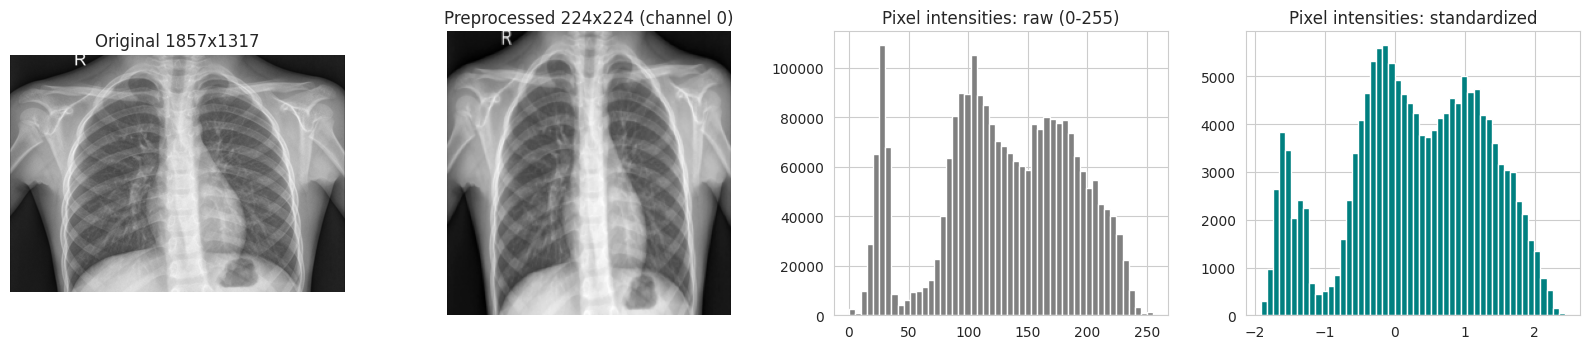

In [ ]:
IMG_SIZE = 224
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32).reshape(3, 1, 1)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32).reshape(3, 1, 1)

def to_tensor(img):
    # PIL image -> standardized float32 array (3, H, W)
    img = img.convert("L").convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    a = np.asarray(img, dtype=np.float32) / 255.0                   # [0, 1]
    a = a.transpose(2, 0, 1)                                        # HWC -> CHW
    return (a - IMAGENET_MEAN) / IMAGENET_STD

def load_and_preprocess(path):
    with Image.open(path) as im:
        return to_tensor(im)

batch_paths = clean_df.groupby("label").head(4)["path"].tolist()
batch = np.stack([load_and_preprocess(p) for p in batch_paths])
print("Batch tensor shape:", batch.shape, "(N, C, H, W) | dtype:", batch.dtype)
print(f"Value range after scaling + standardization: {batch.min():.2f} to {batch.max():.2f}")
print(f"Per-channel mean: {batch.mean(axis=(0, 2, 3)).round(2)} | std: {batch.std(axis=(0, 2, 3)).round(2)}")
print("(Not exactly 0 / 1 because ImageNet statistics are used so pretrained CNNs work; for a model trained from scratch, "
      "compute the mean/std on your own training images instead.)")

# before vs after
p0 = batch_paths[0]
with Image.open(p0) as im0:
    raw = np.asarray(im0.convert("L"))
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
axes[0].imshow(raw, cmap="gray"); axes[0].set_title(f"Original {raw.shape[1]}x{raw.shape[0]}")
axes[1].imshow(batch[0][0], cmap="gray"); axes[1].set_title("Preprocessed 224x224 (channel 0)")
axes[2].hist(raw.ravel(), bins=50, color="gray"); axes[2].set_title("Pixel intensities: raw (0-255)")
axes[3].hist(batch[0].ravel(), bins=50, color="teal"); axes[3].set_title("Pixel intensities: standardized")
for a in axes[:2]: a.axis("off")
plt.tight_layout(); plt.show()

## C5. Data Augmentation
Augmentations chosen for **chest X-rays**:
- small **rotation** (+/-10 degrees) and slight **zoom / shift** (patient positioning varies),
- **brightness / contrast** jitter (different machines and exposure settings),
- **horizontal flip** with p = 0.5 (commonly used for pneumonia detection; a caution: it swaps the heart side, which would be inappropriate if
  laterality matters, e.g. dextrocardia tasks),
- **no vertical flips**, hue/colour changes or heavy crops, which would produce anatomically impossible or finding-removing images.

Augmentation is applied to the **training set only**, and the minority class (NORMAL) is augmented more to counter imbalance.

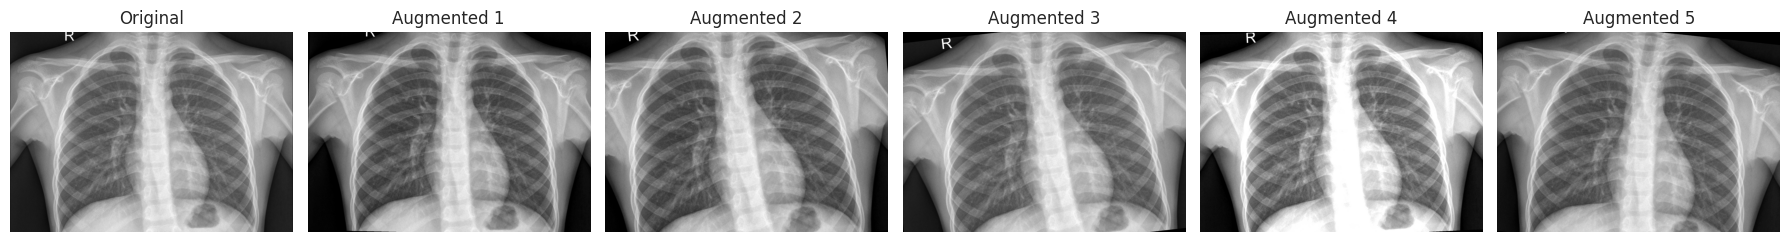

In [ ]:
aug_rng = np.random.default_rng(RANDOM_STATE)

def augment_xray(img, rng=aug_rng):
    img = img.convert("L")
    if rng.random() < 0.5:
        img = ImageOps.mirror(img)                                                    # horizontal flip
    img = img.rotate(float(rng.uniform(-10, 10)), resample=Image.BILINEAR, fillcolor=0)  # rotation
    w, h = img.size; s = rng.uniform(0.88, 1.0)                                       # zoom + shift
    cw, ch = int(w * s), int(h * s)
    x0, y0 = int(rng.integers(0, w - cw + 1)), int(rng.integers(0, h - ch + 1))
    img = img.crop((x0, y0, x0 + cw, y0 + ch)).resize((w, h), Image.BILINEAR)
    img = ImageEnhance.Brightness(img).enhance(float(rng.uniform(0.8, 1.2)))          # brightness
    img = ImageEnhance.Contrast(img).enhance(float(rng.uniform(0.8, 1.2)))            # contrast
    return img

src = clean_df[clean_df["label"] == "NORMAL"]["path"].iloc[0]
with Image.open(src) as im:
    base = im.convert("L")
fig, axes = plt.subplots(1, 6, figsize=(18, 3.2))
axes[0].imshow(base, cmap="gray"); axes[0].set_title("Original")
for k in range(1, 6):
    axes[k].imshow(augment_xray(base), cmap="gray"); axes[k].set_title(f"Augmented {k}")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# how much augmentation is needed to balance the TRAINING set, and the alternative of class weights
train_counts = clean_df[clean_df["split"] == "train"]["label"].value_counts()
major, minor = train_counts.idxmax(), train_counts.idxmin()
need = int(train_counts.max() - train_counts.min())
print(f"Training counts: {train_counts.to_dict()}  (imbalance {train_counts.max()/train_counts.min():.2f}:1)")
print(f"-> generate {need} augmented '{minor}' images to balance the classes.")

n_total = train_counts.sum()
class_weights = {lab: n_total / (2 * n) for lab, n in train_counts.items()}
print("Alternative: class weights for the loss function:", {k: round(v, 2) for k, v in class_weights.items()})

def balanced_batches(df, batch_size=16, seed=0):
    # endless generator: 50/50 class sampling; minority always augmented, majority augmented with p = 0.5
    rng = np.random.default_rng(seed)
    by_label = {lab: g["path"].tolist() for lab, g in df.groupby("label")}
    labels = sorted(by_label)
    while True:
        xs, ys = [], []
        for _ in range(batch_size):
            lab = labels[int(rng.integers(len(labels)))]
            with Image.open(by_label[lab][int(rng.integers(len(by_label[lab])))]) as im:
                im = im.convert("L")
                if lab == minor or rng.random() < 0.5:
                    im = augment_xray(im, rng)
                xs.append(to_tensor(im)); ys.append(int(lab == "PNEUMONIA"))
        yield np.stack(xs), np.array(ys)

xb, yb = next(balanced_batches(clean_df[clean_df["split"] == "train"], batch_size=32))
print(f"\nOne generated batch: images {xb.shape}, labels -> NORMAL {int((yb == 0).sum())} / PNEUMONIA {int((yb == 1).sum())}  (balanced)")

Training counts: {'PNEUMONIA': 3850, 'NORMAL': 1340}  (imbalance 2.87:1)
-> generate 2510 augmented 'NORMAL' images to balance the classes.
Alternative: class weights for the loss function: {'PNEUMONIA': np.float64(0.67), 'NORMAL': np.float64(1.94)}

One generated batch: images (32, 3, 224, 224), labels -> NORMAL 14 / PNEUMONIA 18  (balanced)


## C6. Exploratory Data Analysis

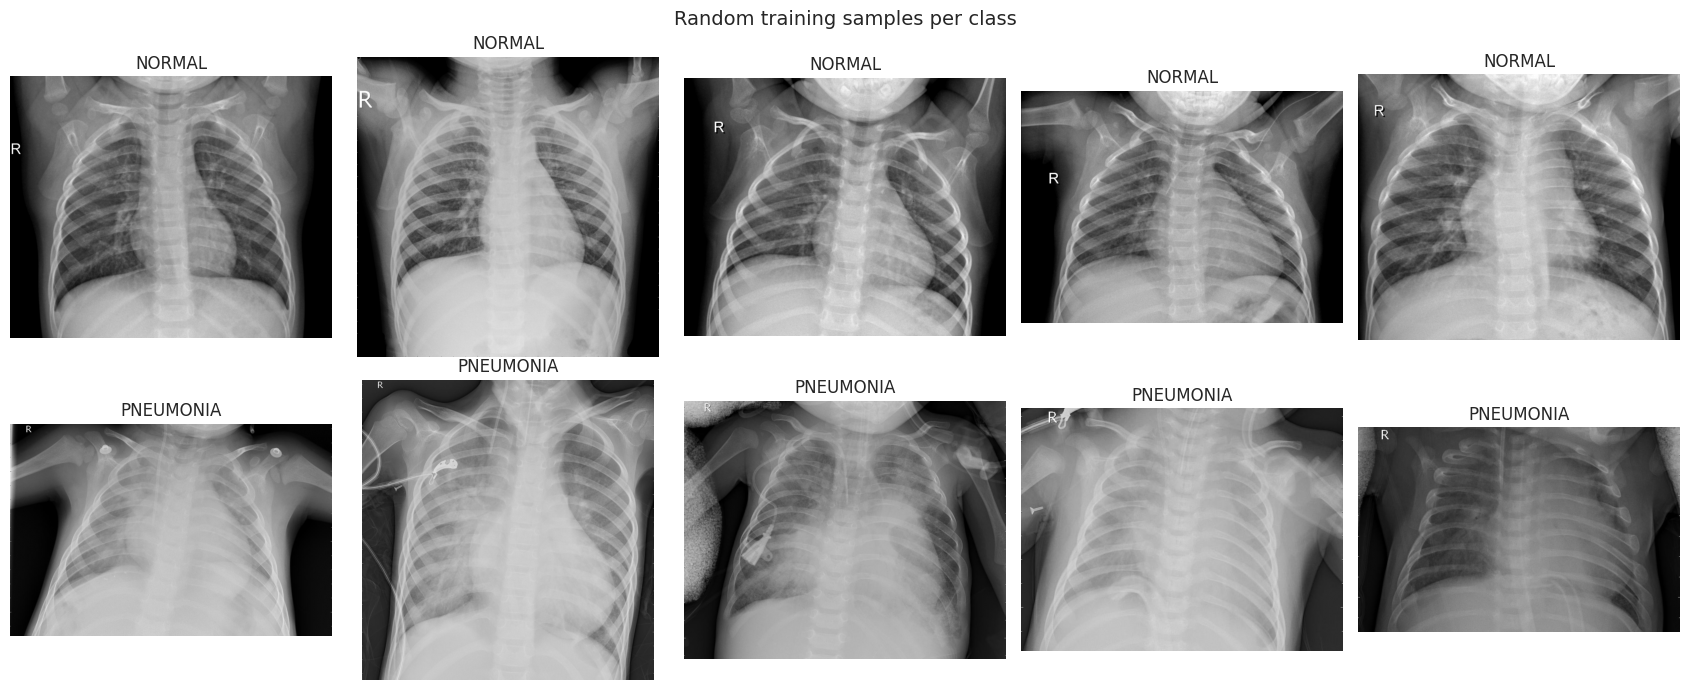

In [ ]:
# sample images per class
fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for r, lab in enumerate(["NORMAL", "PNEUMONIA"]):
    pool = clean_df[(clean_df["label"] == lab) & (clean_df["split"] == "train")]["path"]
    for c, p in enumerate(pool.sample(min(5, len(pool)), random_state=1) if len(pool) else []):
        with Image.open(p) as im:
            axes[r, c].imshow(im.convert("L"), cmap="gray")
        axes[r, c].axis("off"); axes[r, c].set_title(lab)
plt.suptitle("Random training samples per class", fontsize=14); plt.tight_layout(); plt.show()

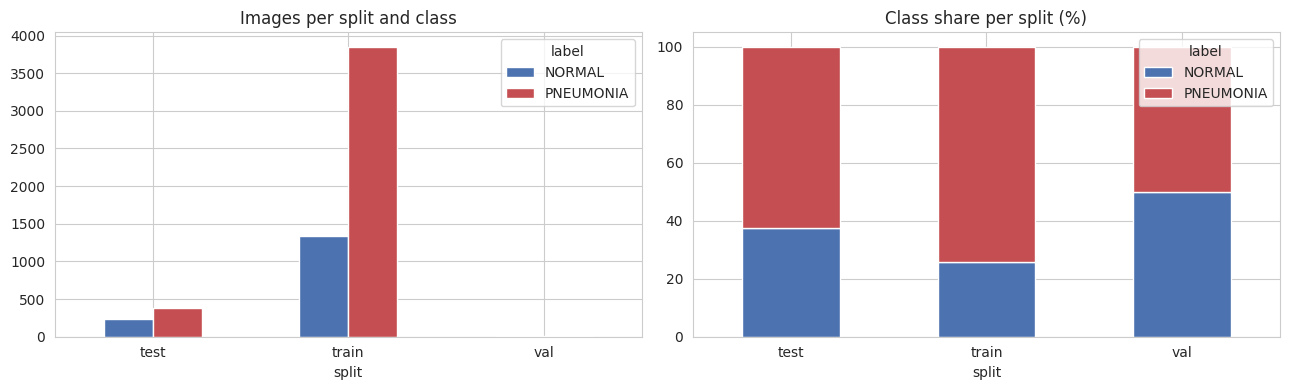

,PNEUMONIA : NORMAL ratio
split,
test,1.68
train,2.87
val,1.00


The validation split is tiny; if it is too small, re-split the training data (stratified) instead of relying on it.


In [ ]:
# quantify class imbalance per split
ct = pd.crosstab(clean_df["split"], clean_df["label"])
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ct.plot(kind="bar", ax=axes[0], rot=0, color=["#4c72b0", "#c44e52"]); axes[0].set_title("Images per split and class")
ct_pct.plot(kind="bar", stacked=True, ax=axes[1], rot=0, color=["#4c72b0", "#c44e52"]); axes[1].set_title("Class share per split (%)")
plt.tight_layout(); plt.show()

imb = (ct["PNEUMONIA"] / ct["NORMAL"]).round(2).rename("PNEUMONIA : NORMAL ratio")
display(imb.to_frame())
print("The validation split is tiny; if it is too small, re-split the training data (stratified) instead of relying on it.")

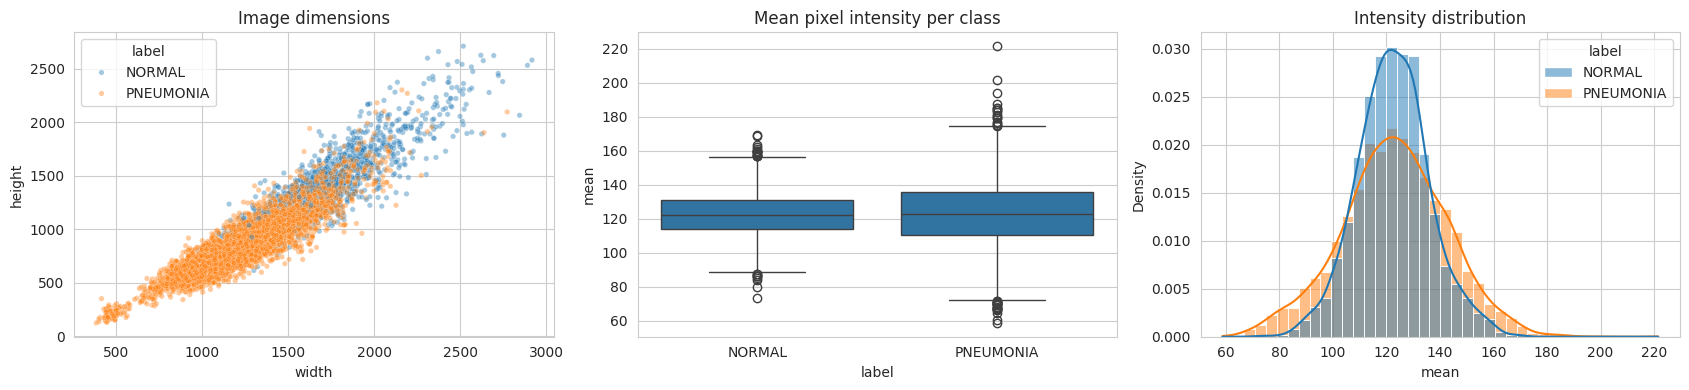

,avg of mean intensity,std of mean intensity
label,,
NORMAL,122.6,13.5
PNEUMONIA,122.8,19.9


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.scatterplot(data=clean_df, x="width", y="height", hue="label", alpha=0.4, s=15, ax=axes[0]); axes[0].set_title("Image dimensions")
sns.boxplot(data=clean_df, x="label", y="mean", ax=axes[1]); axes[1].set_title("Mean pixel intensity per class")
sns.histplot(data=clean_df, x="mean", hue="label", bins=40, kde=True, stat="density", common_norm=False, ax=axes[2]); axes[2].set_title("Intensity distribution")
plt.tight_layout(); plt.show()

d = clean_df.groupby("label")["mean"].agg(["mean", "std"]).round(1)
display(d.rename(columns={"mean": "avg of mean intensity", "std": "std of mean intensity"}))

**Takeaway (Part C):** the dataset is imbalanced (about 3:1 pneumonia:normal in the real data), image sizes vary widely, and
duplicates or cross-split leakage can silently inflate results. Quality filtering, consistent tensors and class-aware
augmentation make the data model-ready. Privacy is handled by stripping DICOM tags and using pixel data only.

---
# Part D: Signal Data (MIT-BIH Arrhythmia Database, ECG)
48 half-hour two-lead ECG recordings sampled at 360 Hz with beat-by-beat expert annotations. We use **record 100**
(first 5 minutes, to keep it fast; set `SAMPLE_TO = None` for the full 30 min).

## D1. Data Acquisition

In [ ]:
import wfdb
from scipy.signal import butter, iirnotch, filtfilt, sosfiltfilt, welch, find_peaks
from scipy.stats import skew, kurtosis
from scipy.integrate import trapezoid

RECORD, SAMPLE_TO = "100", 360 * 60 * 5          # first 5 minutes

def synth_ecg(fs=360, dur=300, seed=1):
    # SYNTHETIC stand-in: Gaussian P-QRS-T beats, HRV, baseline wander, 60 Hz hum, noise, a few ectopic (V) beats.
    rng = np.random.default_rng(seed); n = int(fs * dur); time = np.arange(n) / fs
    beats, t = [], 0.6
    while t < dur - 1:
        beats.append(t); t += 0.83 + 0.05 * np.sin(2*np.pi*0.25*t) + 0.03 * np.sin(2*np.pi*0.1*t) + rng.normal(0, 0.01)
    pvc = set(rng.choice(np.arange(5, len(beats) - 5), 8, replace=False).tolist())
    g = lambda t0, a, w: a * np.exp(-0.5 * ((time - t0) / w) ** 2)
    x, syms = np.zeros(n), []
    for i, b in enumerate(beats):
        if i in pvc:
            x += g(b, 1.5, 0.018) - g(b + 0.05, 0.6, 0.02) + g(b + 0.22, -0.5, 0.07); syms.append("V")
        else:
            x += g(b-0.2, .12, .04) - g(b-0.03, .12, .012) + g(b, 1.0, .012) - g(b+0.03, .25, .012) + g(b+0.25, .3, .06); syms.append("N")
    x += 0.35 * np.sin(2*np.pi*0.3*time) + 0.06 * np.sin(2*np.pi*60*time) + rng.normal(0, 0.02, n)
    sig = np.column_stack([x, 0.6 * x + rng.normal(0, 0.02, n)])
    return sig, fs, np.round(np.array(beats) * fs).astype(int), np.array(syms)

def load_ecg():
    try:
        rec = wfdb.rdrecord(RECORD, pn_dir="mitdb", sampto=SAMPLE_TO)
        ann = wfdb.rdann(RECORD, "atr", pn_dir="mitdb", sampto=SAMPLE_TO)
        meta = {"format": rec.fmt, "adc_gain": rec.adc_gain, "baseline": rec.baseline, "n_sig": rec.n_sig, "comments": rec.comments}
        return rec.p_signal.copy(), rec.fs, list(rec.sig_name), list(rec.units), np.array(ann.sample), np.array(ann.symbol), meta, f"PhysioNet MIT-BIH record {RECORD}"
    except Exception as e:
        print("PhysioNet download failed:", repr(e)[:160])
        sig, fs, idx, sym = synth_ecg()
        meta = {"format": "synthetic", "adc_gain": [200, 200], "baseline": [1024, 1024], "n_sig": 2, "comments": []}
        return sig, fs, ["MLII", "V5"], ["mV", "mV"], idx, sym, meta, "SYNTHETIC stand-in"

sig_all, fs, sig_names, units, ann_idx, ann_sym, meta, ecg_src = load_ecg()
print(f"DATA SOURCE: {ecg_src}" + ("   <-- NOT the real recording" if "SYNTHETIC" in ecg_src else ""))
print("Signal shape        :", sig_all.shape, "(samples x leads)")
print("Sampling rate       :", fs, "Hz")
print("Leads / units       :", sig_names, units)
print("Duration            :", round(len(sig_all) / fs, 1), "s")
print("Record metadata     :", {k: v for k, v in meta.items() if k != "comments"})
print("Number of annotations:", len(ann_idx))
print("Annotation symbols  :", dict(Counter(ann_sym)))

DATA SOURCE: PhysioNet MIT-BIH record 100
Signal shape        : (108000, 2) (samples x leads)
Sampling rate       : 360 Hz
Leads / units       : ['MLII', 'V5'] ['mV', 'mV']
Duration            : 300.0 s
Record metadata     : {'format': ['212', '212'], 'adc_gain': [200.0, 200.0], 'baseline': [1024, 1024], 'n_sig': 2}
Number of annotations: 372
Annotation symbols  : {np.str_('+'): 1, np.str_('N'): 367, np.str_('A'): 4}


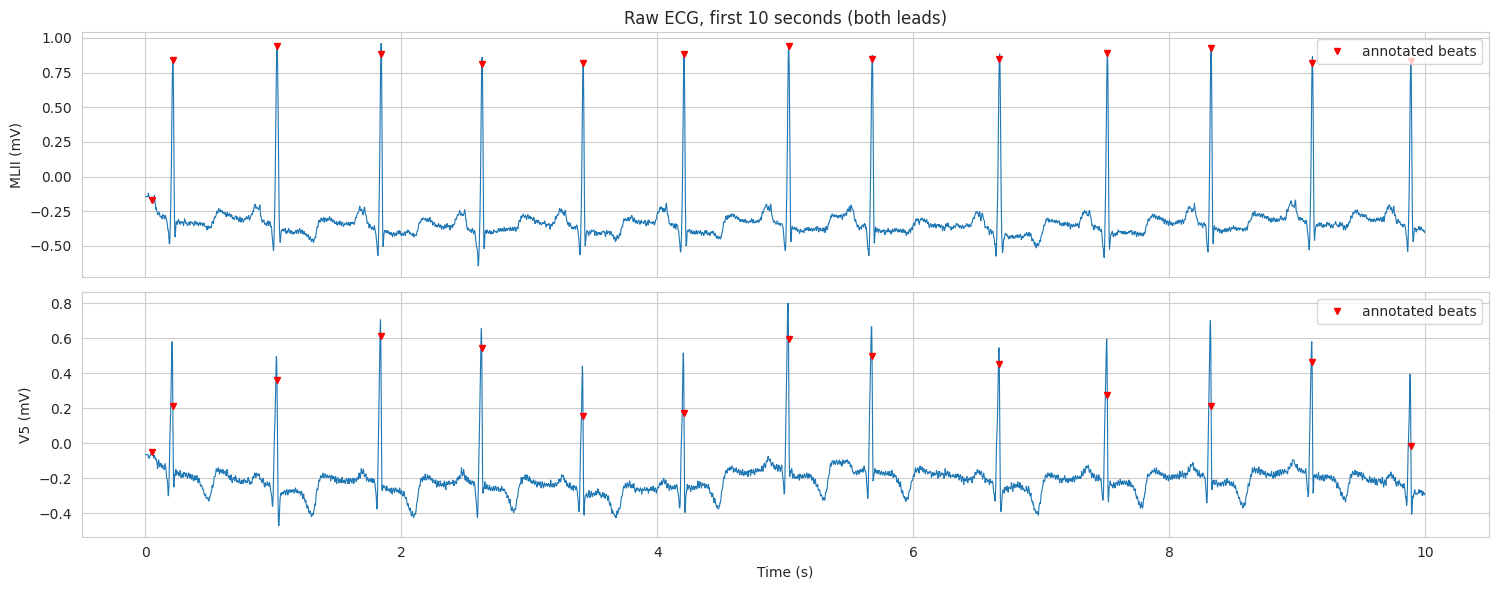

In [ ]:
ecg = sig_all[:, 0]                                  # lead 0 (MLII)
t_full = np.arange(len(ecg)) / fs

fig, axes = plt.subplots(2, 1, figsize=(15, 6), sharex=True)
w = slice(0, 10 * fs)
for k, ax in enumerate(axes):
    ax.plot(t_full[w], sig_all[w, k], lw=0.8)
    sel = ann_idx[ann_idx < 10 * fs]
    ax.plot(sel / fs, sig_all[sel, k], "rv", ms=5, label="annotated beats")
    ax.set_ylabel(f"{sig_names[k]} ({units[k]})"); ax.legend(loc="upper right")
axes[0].set_title("Raw ECG, first 10 seconds (both leads)"); axes[1].set_xlabel("Time (s)")
plt.tight_layout(); plt.show()

## D2. Signal Inspection and Cleaning
Checks on the raw signal:
- **Missing samples:** `NaN` values (WFDB stores invalid ADC samples as NaN after physical conversion).
- **Flatlines:** runs of identical values longer than 0.5 s (lead-off, sensor dropout). A real ECG always has noise.
- **Clipping:** many samples stuck at the global min/max (amplifier saturation).
- **Annotation sanity:** sorted, inside the signal range.

Cleaning: NaN gaps are **linearly interpolated**; flatline/clipped regions are **masked** so no heartbeat is extracted from them.

In [ ]:
def find_runs(mask, min_len):
    # start/end indices of runs of True with length >= min_len
    d = np.diff(np.concatenate([[0], mask.astype(int), [0]]))
    starts, ends = np.where(d == 1)[0], np.where(d == -1)[0]
    return [(s, e) for s, e in zip(starts, ends) if e - s >= min_len]

def inspect_signal(x, fs, label=""):
    n_nan = int(np.isnan(x).sum())
    xx = np.nan_to_num(x, nan=np.nanmedian(x))
    flat = find_runs(np.abs(np.diff(xx, prepend=xx[0])) < 1e-9, int(0.5 * fs))
    lo, hi = xx.min(), xx.max()
    clipped = find_runs((xx >= hi - 1e-9) | (xx <= lo + 1e-9), 5)           # >= 5 consecutive samples at an extreme
    return {"signal": label, "samples": len(x), "NaN samples": n_nan, "flatline segments": len(flat),
            "clipped segments": len(clipped), "min": round(float(lo), 3), "max": round(float(hi), 3)}, flat, clipped

rep, flat_segs, clip_segs = inspect_signal(ecg, fs, "raw ECG (lead 0)")
display(pd.DataFrame([rep]))
print("Annotations sorted:", bool(np.all(np.diff(ann_idx) > 0)), "| inside signal:", bool(ann_idx.max() < len(ecg)))

,signal,samples,NaN samples,flatline segments,clipped segments,min,max
0,raw ECG (lead 0),108000,0,0,0,-0.695,1.245


Annotations sorted: True | inside signal: True


The real recording is usually clean, so to *prove* the checks work we run them on a **deliberately corrupted copy** (3-second flatline, saturated section, 50-sample NaN gap),
then apply the repair.

,signal,samples,NaN samples,flatline segments,clipped segments,min,max
0,corrupted copy,108000,50,1,1,-0.695,2.245


Flatline segments (s): [(np.float64(20.0), np.float64(23.0))]
Clipped segments  (s): [(np.float64(40.0), np.float64(40.17))]

After repair: NaN = 0, samples masked as unusable = 1189 (1.10%)


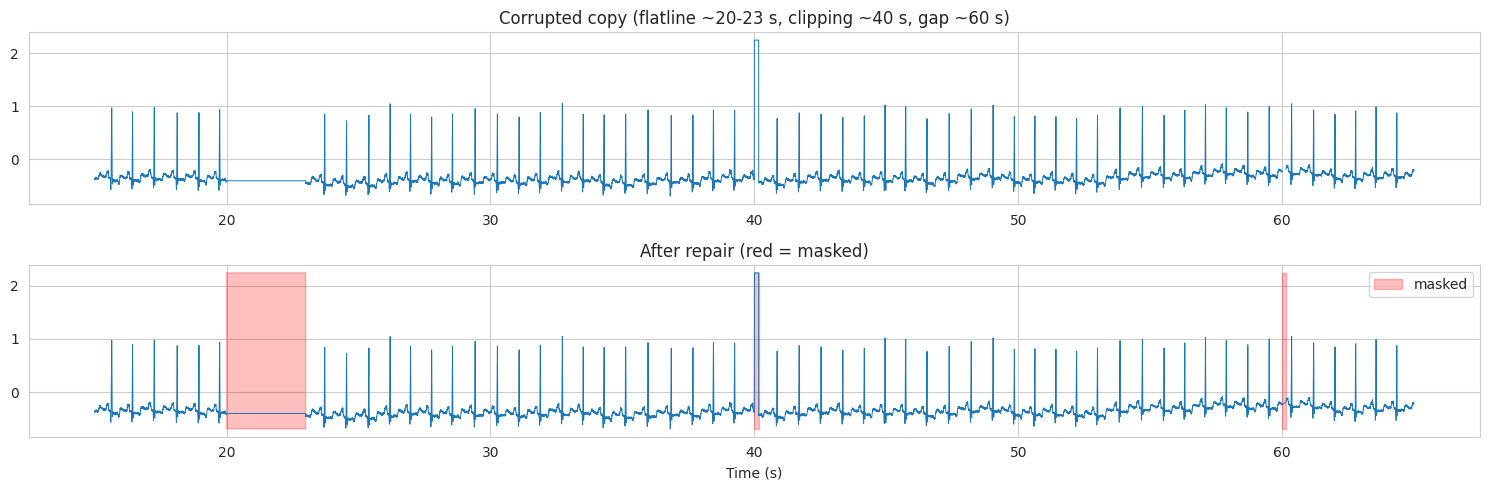

Real signal: samples masked = 0


In [ ]:
demo = ecg.copy()
demo[20*fs:23*fs] = demo[20*fs]                    # 3 s flatline (lead-off)
top = demo.max()
demo[40*fs:40*fs + 60] = top + 1.0                 # saturated section
demo[60*fs:60*fs + 50] = np.nan                    # missing samples

rep_d, flat_d, clip_d = inspect_signal(demo, fs, "corrupted copy")
display(pd.DataFrame([rep_d]))
print("Flatline segments (s):", [(round(s/fs, 2), round(e/fs, 2)) for s, e in flat_d])
print("Clipped segments  (s):", [(round(s/fs, 2), round(e/fs, 2)) for s, e in clip_d])

def repair_signal(x, fs):
    # interpolate NaN gaps, and return (repaired signal, boolean mask of samples that must NOT be used)
    x = x.copy(); bad = np.zeros(len(x), dtype=bool)
    nan = np.isnan(x)
    if nan.any():
        idx = np.arange(len(x)); x[nan] = np.interp(idx[nan], idx[~nan], x[~nan]); bad |= nan
    _, flat, clip = inspect_signal(x, fs)
    for s, e in flat + clip:
        bad[s:e] = True
    return x, bad

demo_fixed, demo_bad = repair_signal(demo, fs)
print(f"\nAfter repair: NaN = {int(np.isnan(demo_fixed).sum())}, samples masked as unusable = {int(demo_bad.sum())} ({demo_bad.mean():.2%})")

fig, axes = plt.subplots(2, 1, figsize=(15, 5), sharex=False)
axes[0].plot(t_full[15*fs:65*fs], demo[15*fs:65*fs], lw=0.7); axes[0].set_title("Corrupted copy (flatline ~20-23 s, clipping ~40 s, gap ~60 s)")
axes[1].plot(t_full[15*fs:65*fs], demo_fixed[15*fs:65*fs], lw=0.7)
axes[1].fill_between(t_full[15*fs:65*fs], demo_fixed[15*fs:65*fs].min(), demo_fixed[15*fs:65*fs].max(), where=demo_bad[15*fs:65*fs], color="red", alpha=0.25, label="masked")
axes[1].set_title("After repair (red = masked)"); axes[1].legend(); axes[1].set_xlabel("Time (s)")
plt.tight_layout(); plt.show()

# real signal: apply the same repair (usually a no-op)
ecg_fixed, bad_mask = repair_signal(ecg, fs)
print(f"Real signal: samples masked = {int(bad_mask.sum())}")

## D3. Noise Removal / Filtering
| Noise | Cause | Remedy |
|---|---|---|
| **Baseline wander** (< 0.5 Hz) | breathing, electrode movement | high-pass at 0.5 Hz |
| **Powerline interference** (60 Hz in the US where MIT-BIH was recorded; 50 Hz in India/Europe) | mains hum | notch filter |
| High-frequency / muscle noise (> 40 Hz) | EMG, sensor noise | low-pass at 40 Hz |

Zero-phase filtering (`filtfilt` / `sosfiltfilt`) is used so the QRS complexes are not shifted in time.

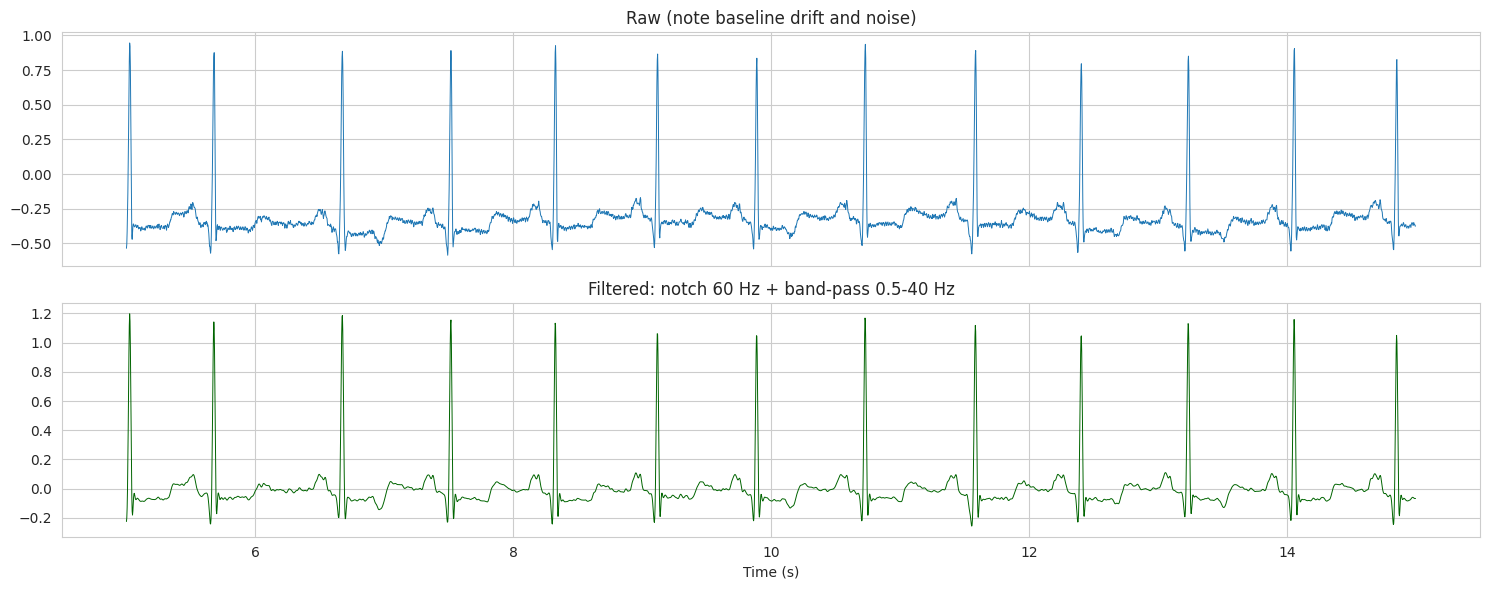

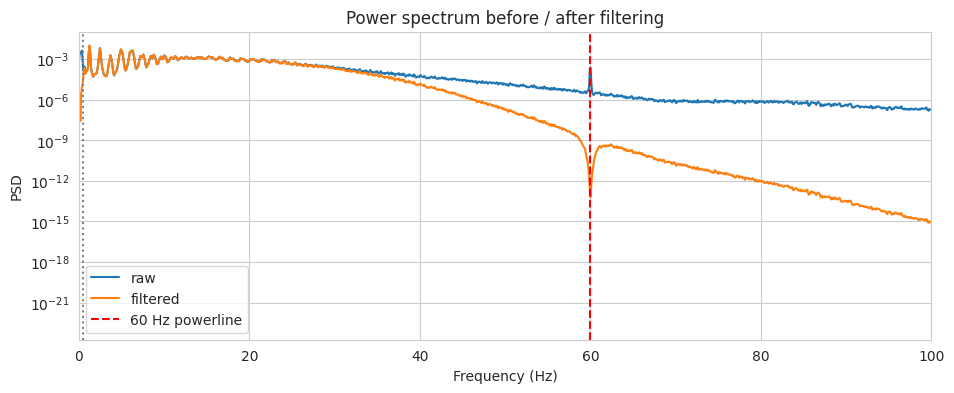

Power near 60 Hz (+/-1): raw 4.48e-05 -> filtered 2.25e-10
Power below 0.5 Hz     : raw 1.19e-03 -> filtered 1.79e-06


In [ ]:
POWERLINE_HZ = 60

def remove_noise(x, fs, notch_hz=POWERLINE_HZ, band=(0.5, 40.0)):
    b, a = iirnotch(notch_hz, Q=30, fs=fs)                       # powerline notch
    x = filtfilt(b, a, x)
    sos = butter(4, band, btype="bandpass", fs=fs, output="sos") # baseline wander + HF noise
    return sosfiltfilt(sos, x)

ecg_filt = remove_noise(ecg_fixed, fs)

seg = slice(5 * fs, 15 * fs)
fig, axes = plt.subplots(2, 1, figsize=(15, 6), sharex=True)
axes[0].plot(t_full[seg], ecg_fixed[seg], lw=0.7); axes[0].set_title("Raw (note baseline drift and noise)")
axes[1].plot(t_full[seg], ecg_filt[seg], lw=0.7, color="darkgreen"); axes[1].set_title("Filtered: notch 60 Hz + band-pass 0.5-40 Hz"); axes[1].set_xlabel("Time (s)")
plt.tight_layout(); plt.show()

# spectral proof
f1, p1 = welch(ecg_fixed, fs=fs, nperseg=4096); f2, p2 = welch(ecg_filt, fs=fs, nperseg=4096)
plt.figure(figsize=(11, 4))
plt.semilogy(f1, p1, label="raw"); plt.semilogy(f2, p2, label="filtered")
plt.axvline(POWERLINE_HZ, color="r", ls="--", label=f"{POWERLINE_HZ} Hz powerline"); plt.axvline(0.5, color="gray", ls=":")
plt.xlim(0, 100); plt.xlabel("Frequency (Hz)"); plt.ylabel("PSD"); plt.title("Power spectrum before / after filtering"); plt.legend(); plt.show()

def band_power(f, p, lo, hi):
    m = (f >= lo) & (f <= hi); return trapezoid(p[m], f[m])
print(f"Power near {POWERLINE_HZ} Hz (+/-1): raw {band_power(f1, p1, POWERLINE_HZ-1, POWERLINE_HZ+1):.2e} -> filtered {band_power(f2, p2, POWERLINE_HZ-1, POWERLINE_HZ+1):.2e}")
print(f"Power below 0.5 Hz     : raw {band_power(f1, p1, 0, 0.5):.2e} -> filtered {band_power(f2, p2, 0, 0.5):.2e}")

## D4. Segmentation: R-peak Detection and Heartbeat Windows
1. Detect QRS complexes with WFDB's **XQRS** detector, then snap each detection to the local maximum of |signal| (the R-peak).
2. Check the detector against the expert annotations (tolerance +/-150 ms): **sensitivity** and **positive predictivity**.
3. Cut a fixed window around every R-peak (0.25 s before, 0.40 s after = 234 samples), skipping beats near the signal edges
   or overlapping a masked (bad) region.
4. Label each beat with the nearest expert annotation, mapped to AAMI classes: **N** normal, **S** supraventricular, **V** ventricular, **F** fusion, **Q** unknown.

Reference beats: 371 | detected R-peaks: 371
Sensitivity            : 1.000
Positive predictivity  : 1.000


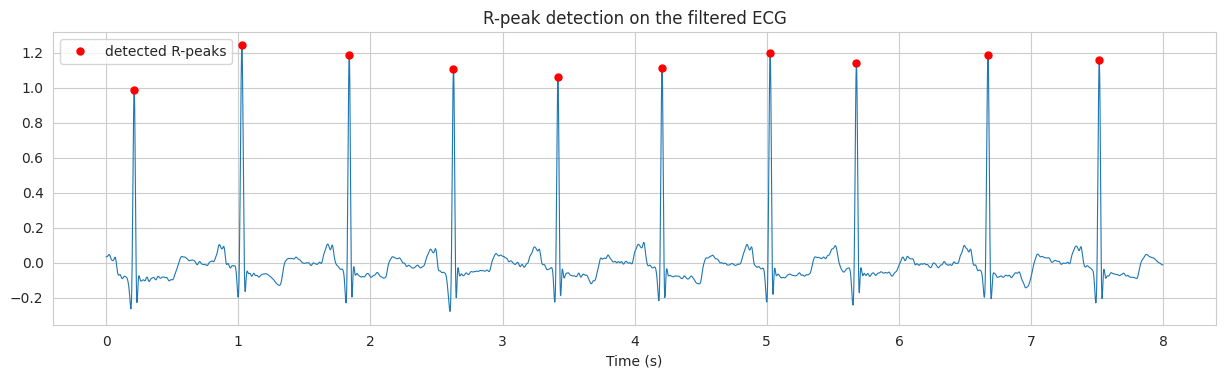

In [ ]:
from wfdb import processing

def detect_rpeaks(x, fs):
    try:
        peaks = np.array(processing.xqrs_detect(sig=x, fs=fs, verbose=False))
    except Exception as e:
        print("XQRS failed, using find_peaks fallback:", repr(e)[:80])
        peaks, _ = find_peaks(np.abs(x), height=np.percentile(np.abs(x), 98), distance=int(0.25 * fs))
    r = int(0.05 * fs); snapped = []
    for p in peaks:                                                     # snap to the true R-peak (max |amplitude|)
        lo, hi = max(0, p - r), min(len(x), p + r + 1)
        snapped.append(lo + int(np.argmax(np.abs(x[lo:hi]))))
    return np.unique(np.array(snapped))

rpeaks = detect_rpeaks(ecg_filt, fs)

# ---- evaluate against the expert annotations
BEAT_SYMBOLS = set("NLRBAaJSVrFejnE/fQ?")
ref = ann_idx[np.array([s in BEAT_SYMBOLS for s in ann_sym])]
tol = int(0.15 * fs)

def nearest_dist(a, b):
    i = np.clip(np.searchsorted(b, a), 1, len(b) - 1)
    return np.minimum(np.abs(a - b[i - 1]), np.abs(a - b[i]))

TP_ref = int((nearest_dist(ref, rpeaks) <= tol).sum())          # reference beats that were found
TP_det = int((nearest_dist(rpeaks, ref) <= tol).sum())          # detections that match a reference beat
print(f"Reference beats: {len(ref)} | detected R-peaks: {len(rpeaks)}")
print(f"Sensitivity            : {TP_ref / len(ref):.3f}")
print(f"Positive predictivity  : {TP_det / len(rpeaks):.3f}")

w = slice(0, 8 * fs)
plt.figure(figsize=(15, 3.8))
plt.plot(t_full[w], ecg_filt[w], lw=0.8)
pk = rpeaks[rpeaks < 8 * fs]
plt.plot(pk / fs, ecg_filt[pk], "ro", ms=5, label="detected R-peaks")
plt.title("R-peak detection on the filtered ECG"); plt.xlabel("Time (s)"); plt.legend(); plt.show()

Beat matrix: (370, 234) (beats x samples per window)
Class distribution (AAMI): {np.str_('N'): 366, np.str_('S'): 4} -> heavily imbalanced


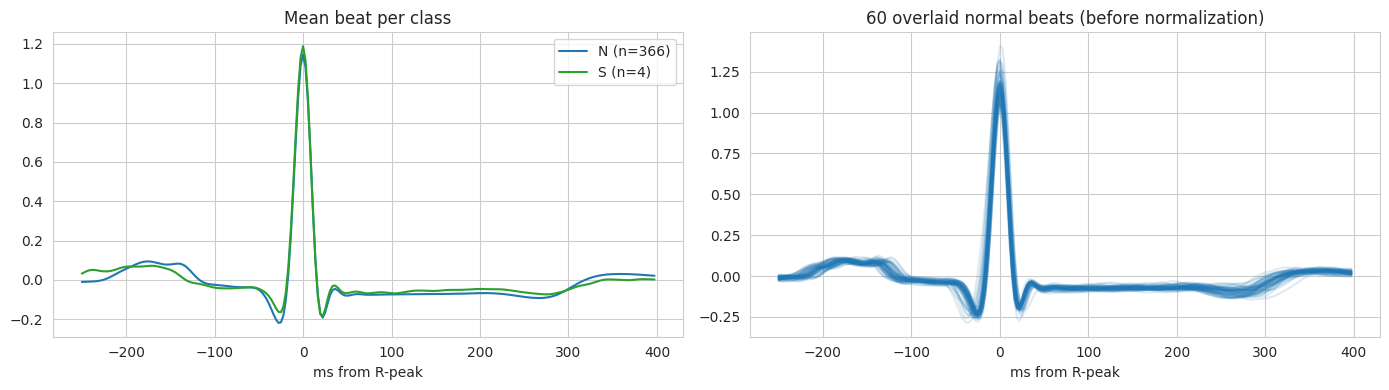

In [ ]:
AAMI = {"N": "N", "L": "N", "R": "N", "e": "N", "j": "N",
        "A": "S", "a": "S", "J": "S", "S": "S",
        "V": "V", "E": "V", "F": "F", "/": "Q", "f": "Q", "Q": "Q"}

PRE, POST = int(0.25 * fs), int(0.40 * fs)
beat_ann = ann_idx[np.array([s in AAMI for s in ann_sym])]
beat_lab = np.array([AAMI[s] for s in ann_sym if s in AAMI])

windows, meta_rows = [], []
for k, p in enumerate(rpeaks):
    if p - PRE < 0 or p + POST > len(ecg_filt):            continue          # too close to the edge
    if bad_mask[p - PRE:p + POST].any():                  continue          # overlaps a bad region
    j = int(np.argmin(np.abs(beat_ann - p)))
    label = beat_lab[j] if abs(beat_ann[j] - p) <= tol else "Q"
    rr_prev = (p - rpeaks[k - 1]) / fs * 1000 if k > 0 else np.nan
    rr_next = (rpeaks[k + 1] - p) / fs * 1000 if k < len(rpeaks) - 1 else np.nan
    windows.append(ecg_filt[p - PRE:p + POST]); meta_rows.append({"r_sample": p, "label": label, "rr_prev_ms": rr_prev, "rr_next_ms": rr_next})

beats = np.stack(windows); beat_df = pd.DataFrame(meta_rows)
print("Beat matrix:", beats.shape, "(beats x samples per window)")
print("Class distribution (AAMI):", beat_df["label"].value_counts().to_dict(), "-> heavily imbalanced")

tw = (np.arange(-PRE, POST) / fs) * 1000
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for lab, col in [("N", "tab:blue"), ("V", "tab:red"), ("S", "tab:green")]:
    sel = beats[beat_df["label"].values == lab]
    if len(sel):
        axes[0].plot(tw, sel.mean(axis=0), color=col, label=f"{lab} (n={len(sel)})")
axes[0].set_title("Mean beat per class"); axes[0].set_xlabel("ms from R-peak"); axes[0].legend()
for b in beats[beat_df["label"].values == "N"][:60]:
    axes[1].plot(tw, b, color="tab:blue", alpha=0.15)
axes[1].set_title("60 overlaid normal beats (before normalization)"); axes[1].set_xlabel("ms from R-peak")
plt.tight_layout(); plt.show()

## D5. Feature Extraction
### Time-domain HRV (from RR intervals)
Physiologically implausible RR intervals (< 300 ms or > 2000 ms) and intervals deviating > 20% from the local median
(missed / extra detections, ectopic beats) are removed first, giving *NN intervals*.
- **Mean RR, mean HR**, **SDNN** (overall variability), **RMSSD** (beat-to-beat, vagal tone), **pNN50** (% successive differences > 50 ms).

### Frequency-domain HRV
The NN series is resampled to an evenly spaced 4 Hz signal and its Welch power spectrum is integrated over
**VLF** (0.003-0.04 Hz), **LF** (0.04-0.15 Hz, sympathetic + parasympathetic) and **HF** (0.15-0.40 Hz, parasympathetic / breathing); **LF/HF** is a commonly used balance index.

RR intervals: 370 | kept as NN intervals: 365 (98.6%)


,value
mean_RR_ms,809.437
mean_HR_bpm,74.126
SDNN_ms,28.614
RMSSD_ms,32.082
pNN50_%,5.495
min_RR_ms,652.778
max_RR_ms,961.111
VLF_power_ms2,14.592
LF_power_ms2,47.075
HF_power_ms2,512.170


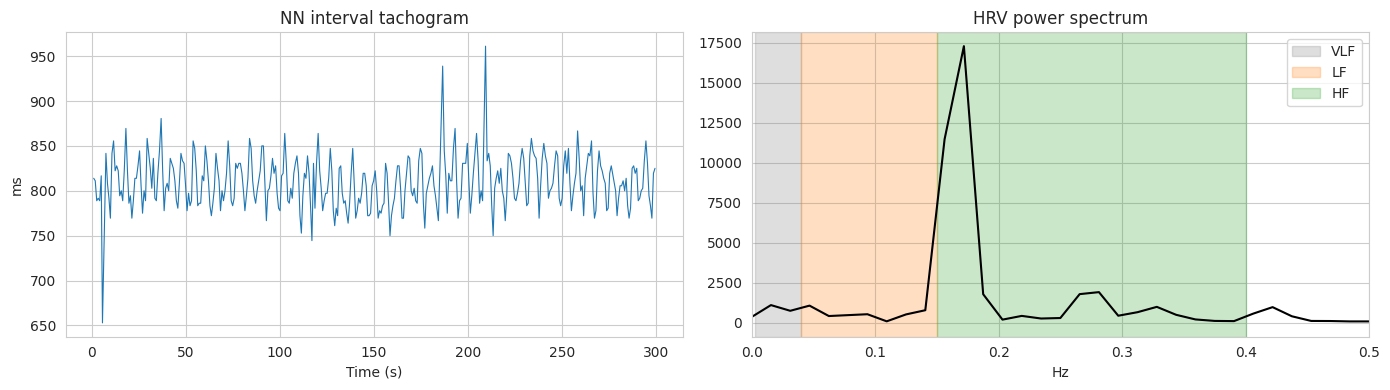

In [ ]:
from scipy.ndimage import median_filter
from scipy.interpolate import interp1d

rr = np.diff(rpeaks) / fs * 1000                                   # ms
t_rr = rpeaks[1:] / fs                                             # time of the end of each interval (s)
med = median_filter(rr, size=7, mode="nearest")
valid = (rr > 300) & (rr < 2000) & (np.abs(rr - med) < 0.2 * med)
nn, t_nn = rr[valid], t_rr[valid]
print(f"RR intervals: {len(rr)} | kept as NN intervals: {len(nn)} ({len(nn)/len(rr):.1%})")

hrv = {"mean_RR_ms": nn.mean(), "mean_HR_bpm": 60000 / nn.mean(), "SDNN_ms": nn.std(ddof=1),
       "RMSSD_ms": np.sqrt(np.mean(np.diff(nn) ** 2)), "pNN50_%": np.mean(np.abs(np.diff(nn)) > 50) * 100,
       "min_RR_ms": nn.min(), "max_RR_ms": nn.max()}

# frequency domain
FS_RESAMPLE = 4.0
tt = np.arange(t_nn[0], t_nn[-1], 1 / FS_RESAMPLE)
nn_even = interp1d(t_nn, nn, kind="cubic", fill_value="extrapolate")(tt)
nn_even = sp_signal.detrend(nn_even)
f_h, p_h = welch(nn_even, fs=FS_RESAMPLE, nperseg=min(256, len(nn_even)), noverlap=min(128, len(nn_even) // 2))

bands = {"VLF": (0.003, 0.04), "LF": (0.04, 0.15), "HF": (0.15, 0.40)}
for name, (lo, hi) in bands.items():
    hrv[f"{name}_power_ms2"] = band_power(f_h, p_h, lo, hi)
hrv["LF/HF"] = hrv["LF_power_ms2"] / hrv["HF_power_ms2"]
hrv["total_power_ms2"] = sum(hrv[f"{b}_power_ms2"] for b in bands)
hrv["LF_norm_%"] = 100 * hrv["LF_power_ms2"] / (hrv["LF_power_ms2"] + hrv["HF_power_ms2"])
hrv["HF_norm_%"] = 100 - hrv["LF_norm_%"]

display(pd.Series(hrv, name="value").round(3).to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(t_nn, nn, lw=0.8); axes[0].set_title("NN interval tachogram"); axes[0].set_xlabel("Time (s)"); axes[0].set_ylabel("ms")
axes[1].plot(f_h, p_h, color="k")
for (name, (lo, hi)), c in zip(bands.items(), ["tab:gray", "tab:orange", "tab:green"]):
    axes[1].axvspan(lo, hi, color=c, alpha=0.25, label=name)
axes[1].set_xlim(0, 0.5); axes[1].set_title("HRV power spectrum"); axes[1].set_xlabel("Hz"); axes[1].legend()
plt.tight_layout(); plt.show()

### Per-beat feature table and ECG spectral power
For machine-learning use, each heartbeat also gets a feature vector: the RR context (`rr_prev`, `rr_next`, their ratio — premature beats have a short `rr_prev` and long `rr_next`),
R amplitude, peak-to-peak amplitude, QRS area, energy, skewness and kurtosis of the window. Spectral power of the filtered ECG
is split into clinically meaningful bands.

In [ ]:
qrs_half = int(0.06 * fs)
feat = pd.DataFrame({
    "rr_prev_ms": beat_df["rr_prev_ms"], "rr_next_ms": beat_df["rr_next_ms"],
    "rr_ratio": beat_df["rr_prev_ms"] / beat_df["rr_next_ms"],
    "r_amplitude": beats[:, PRE],
    "peak_to_peak": beats.max(axis=1) - beats.min(axis=1),
    "qrs_area": np.abs(beats[:, PRE - qrs_half:PRE + qrs_half]).sum(axis=1) / fs,
    "energy": (beats ** 2).sum(axis=1) / fs,
    "skewness": skew(beats, axis=1), "kurtosis": kurtosis(beats, axis=1),
})
feat = feat.fillna(feat.median())                       # first/last beat have no neighbour RR
feat["label"] = beat_df["label"].values
display(feat.head())

# ECG spectral power (relative) per physiologic band
f_e, p_e = welch(ecg_filt, fs=fs, nperseg=2048)
tot = band_power(f_e, p_e, 0.5, 40)
ecg_bands = {"0.5-5 Hz (P/T waves)": (0.5, 5), "5-15 Hz (QRS energy)": (5, 15), "15-40 Hz (high freq / noise)": (15, 40)}
display(pd.Series({k: band_power(f_e, p_e, *v) / tot * 100 for k, v in ecg_bands.items()}, name="% of 0.5-40 Hz power").round(1).to_frame())

,rr_prev_ms,rr_next_ms,rr_ratio,r_amplitude,peak_to_peak,qrs_area,energy,skewness,kurtosis,label
0,813.888889,811.111111,1.003425,1.240712,1.438155,0.032709,0.027421,4.299130,19.951721,N
1,811.111111,788.888889,1.028169,1.183308,1.413517,0.029180,0.022279,4.521138,23.002596,N
2,788.888889,791.666667,0.996491,1.104985,1.383741,0.030915,0.020119,4.301501,21.813253,N
3,791.666667,788.888889,1.003521,1.060501,1.285980,0.026377,0.017956,4.367916,22.079963,N
4,788.888889,816.666667,0.965986,1.113203,1.330743,0.027798,0.020700,4.185814,20.514719,N


,% of 0.5-40 Hz power
0.5-5 Hz (P/T waves),14.7
5-15 Hz (QRS energy),43.5
15-40 Hz (high freq / noise),38.8


## D6. Normalization
- **Beat windows:** per-beat **z-score** (mean 0, std 1) removes amplitude differences caused by electrode placement and gain,
  so the model learns *shape*. A min-max alternative (0-1) is shown too.
- **Feature vectors:** `StandardScaler` (fit on the training portion only when modelling).

z-score  : mean 0.000, std 1.000
min-max  : min 0.00, max 1.00


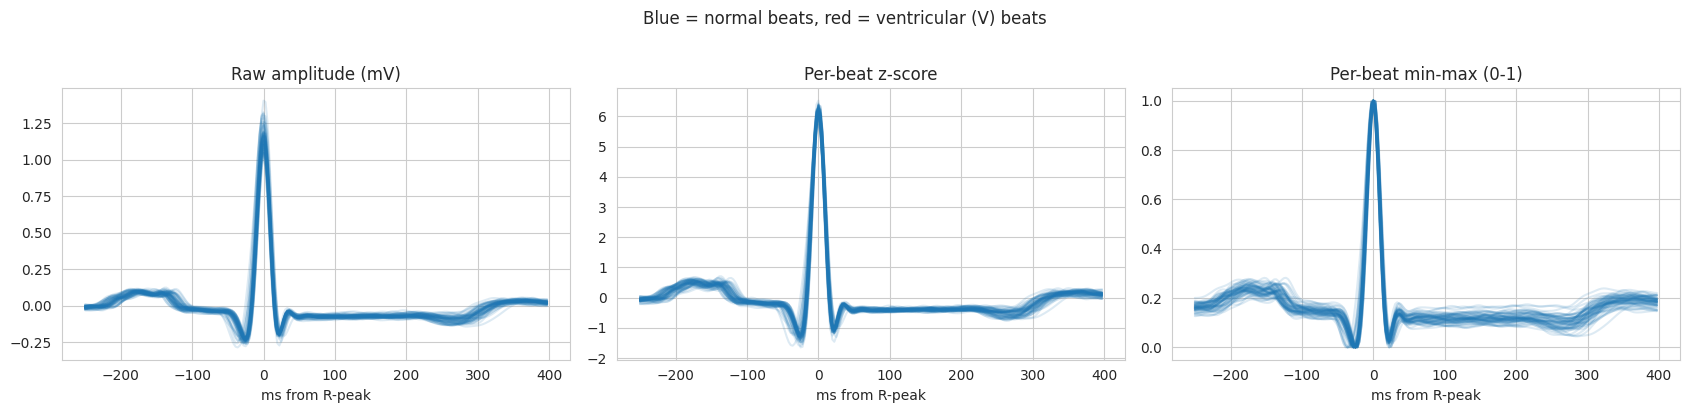

In [ ]:
def zscore_beats(b):
    return (b - b.mean(axis=1, keepdims=True)) / (b.std(axis=1, keepdims=True) + 1e-8)

def minmax_beats(b):
    mn, mx = b.min(axis=1, keepdims=True), b.max(axis=1, keepdims=True)
    return (b - mn) / (mx - mn + 1e-8)

beats_z, beats_mm = zscore_beats(beats), minmax_beats(beats)
print(f"z-score  : mean {beats_z.mean():.3f}, std {beats_z.std():.3f}")
print(f"min-max  : min {beats_mm.min():.2f}, max {beats_mm.max():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharex=True)
for ax, data, ttl in zip(axes, [beats, beats_z, beats_mm], ["Raw amplitude (mV)", "Per-beat z-score", "Per-beat min-max (0-1)"]):
    for b in data[beat_df["label"].values == "N"][:60]:
        ax.plot(tw, b, color="tab:blue", alpha=0.15)
    v = data[beat_df["label"].values == "V"][:5]
    for b in v: ax.plot(tw, b, color="tab:red", alpha=0.8)
    ax.set_title(ttl); ax.set_xlabel("ms from R-peak")
plt.suptitle("Blue = normal beats, red = ventricular (V) beats", y=1.02); plt.tight_layout(); plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler as _SS

num_feats = feat.drop(columns="label")
feat_scaled = pd.DataFrame(_SS().fit_transform(num_feats), columns=num_feats.columns)
feat_scaled["label"] = feat["label"].values
print("Scaled feature table (mean ~0, std ~1):")
display(feat_scaled.drop(columns="label").describe().loc[["mean", "std"]].round(2))

print(f"\nFinal model-ready ECG data -> beat windows {beats_z.shape} | feature matrix {num_feats.shape} | labels {feat['label'].value_counts().to_dict()}")
print("Note: normal beats dominate, so a classifier needs resampling / class weights and per-patient (not per-beat) train/test splits.")

Scaled feature table (mean ~0, std ~1):


,rr_prev_ms,rr_next_ms,rr_ratio,r_amplitude,peak_to_peak,qrs_area,energy,skewness,kurtosis
mean,0.0,0.0,0.0,0.0,0.0,-0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0



Final model-ready ECG data -> beat windows (370, 234) | feature matrix (370, 9) | labels {np.str_('N'): 366, np.str_('S'): 4}
Note: normal beats dominate, so a classifier needs resampling / class weights and per-patient (not per-beat) train/test splits.


**Takeaway (Part D):** raw ECG contains baseline drift and powerline hum; zero-phase filtering removes them without distorting the QRS. Reliable R-peak
detection (checked against expert labels) allows beat segmentation, HRV and per-beat features, and normalization makes amplitudes comparable.
Beat classes are heavily imbalanced, and artefact checks keep corrupted segments out of the training data.

---
# Overall Conclusions: Why Healthcare Data Needs Extra Rigor
| Challenge | Where it appeared | How it was handled |
|---|---|---|
| Missingness hidden as valid-looking values | Pima: zeros in Glucose, BP, BMI, Insulin | Zero -> NaN, median imputation, missing-indicator features |
| Privacy / PHI | MTSamples text; DICOM headers | Regex redaction of names, dates, MRN, phone; DICOM tag blanking, pixel-only pipeline |
| Class imbalance | Pima (~65:35), X-ray (~3:1), ECG beats (mostly normal) | Stratified splits, class weights, targeted augmentation, AUC / recall metrics |
| Duplicates and leakage | Pima rows; X-ray near-duplicates across splits | Exact + perceptual-hash de-duplication, split-aware removal |
| Noise and artefacts | ECG baseline wander, 60 Hz hum, flatlines, clipping | Notch + band-pass filters, artefact masks, interpolation |
| Inference, not only prediction | Pima | t-tests, chi-square tests, effect sizes, multiple-testing correction |